# Невский район: кварталы, застройка, школы и доступность

Учебное исследование для Windows · **BlocksNet 1.0.0a9** · Python 3.10.

**Вопрос исследования:** как различаются кварталы Невского района Санкт-Петербурга
по характеру застройки, расчётному населению, вместимости школ и автомобильной доступности?

Ноутбук подготовлен без выполнения ячеек. Загрузки и расчёты начинаются только при вашем запуске.
Первый сеанс заканчивается после подготовки кварталов. После этого спросите в чате о метриках.
Не запускайте сразу все ячейки: используйте **Shift+Enter** — выполнить ячейку и перейти к следующей.

Порядок: настройки → граница → исходные линии → кварталы → **ОСТАНОВКА** →
землепользование → здания и школы → готовая сеть → время в пути → показатели → проверка и выводы.

Основа: [pipeline.ipynb](https://github.com/aimclub/blocksnet/blob/main/examples/pipeline.ipynb).
Пример на GitHub может меняться. Здесь использован API установленной версии 1.0.0a9;
в частности, `area_accessibility` импортируется из `blocksnet.analysis.network`.

## 0. Открыть ноутбук в Windows

В PowerShell из папки проекта:

```powershell
cd C:\games\urban\python-package-boilerplate
.\.venv\Scripts\python.exe -m pip install -e ".[research]"
.\.venv\Scripts\python.exe -m ipykernel install --prefix .\.venv --name nevsky-blocksnet --display-name "Nevsky (BlocksNet 1.0.0a9)"
.\.venv\Scripts\python.exe -m jupyter notebook .\examples\nevsky_research.ipynb
```

Установка нужна при первом запуске или изменении зависимостей; они записаны в `pyproject.toml`.
В Jupyter выберите ядро **Nevsky (BlocksNet 1.0.0a9)**. Команда регистрации ядра нужна один раз.
Если редактор предлагает выбрать Python, укажите `.venv\Scripts\python.exe` проекта.
Если появляется `ModuleNotFoundError`, сначала проверьте этот выбор, затем повторите установку.
Не используйте обычный `pip`: он может относиться к другому Python.

В ноутбуке не требуется вводить команды установки. Для остановки долгой ячейки нажмите **■ Stop**.
Первый импорт библиотек иногда занимает несколько минут. Пока рядом с ячейкой стоит `[*]`,
она выполняется. Само по себе предупреждение `FutureWarning` не означает остановку с ошибкой.
После перезапуска ядра выполняйте ячейки сверху вниз: сохранённые файлы восстановят состояние.

In [1]:
from pathlib import Path
from importlib.metadata import version
import sys

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents] if (p / 'pyproject.toml').is_file()), None)
assert ROOT is not None, 'Откройте ноутбук из папки учебного проекта.'
expected_python = ROOT / '.venv' / 'Scripts' / 'python.exe'
assert Path(sys.executable).resolve() == expected_python.resolve(), (
    f'Выберите Python: {expected_python}. Сейчас используется {sys.executable}'
)
assert version('blocksnet') == '1.0.0a9', 'Требуется BlocksNet именно 1.0.0a9.'
print('Python:', sys.executable)
for package in ['blocksnet', 'geopandas', 'osmnx', 'networkx', 'scipy', 'sumolib']:
    print(f'{package}: {version(package)}')

Python: C:\games\urban\python-package-boilerplate\.venv\Scripts\python.exe
blocksnet: 1.0.0a9
geopandas: 1.1.4
osmnx: 2.0.7
networkx: 3.4.2
scipy: 1.15.3
sumolib: 1.28.0


## 1. Настройки и сохранение

Первый раз оставьте настройки как есть. `REFRESH_RAW=False` означает: использовать уже
сохранённые исходные данные. Переключайте его в `True` только для намеренного обновления
OpenStreetMap и файла сети. Затем верните `False`.

`REFRESH_DERIVED=True` пересчитывает подготовленные результаты из сохранённых исходников.
При обычном повторном запуске оставьте оба значения `False`.
Параметры, версии библиотек и контрольные суммы файлов проверяются автоматически;
устаревшие производные результаты пересоздаются, несовместимые исходники вызывают понятную остановку.
При ручном изменении алгоритмов увеличьте `CACHE_SCHEMA`.

GeoJSON хранится в долготе/широте (EPSG:4326), а площади и расстояния считаются в метрах
в EPSG:32636. Пустые результаты также сохраняются. Номера объектов записываются отдельным полем.
Следующая большая ячейка содержит служебные функции: просто выполните её, редактировать код не требуется.

In [2]:
PLACE = 'Невский район, Санкт-Петербург, Россия'
LOCAL_EPSG = 32636
REFRESH_RAW = False
REFRESH_DERIVED = False
CACHE_SCHEMA = 'nevsky-2'
DEFAULT_FLOORS = 1
LIVING_AREA_COEFFICIENT = 0.9
LIVING_M2_PER_PERSON = 30.0  # как в pipeline, оценка, не статистика населения
SPACEMATRIX_CLUSTERS = 11
RANDOM_STATE = 42
MAX_SNAP_DISTANCE_M = 1500.0
SCHOOL_CAR_THRESHOLD_MIN = None  # None: значение из конфигурации BlocksNet, учебный сценарий

DATA = ROOT / 'examples' / 'data' / 'nevsky'
RAW, READY, RESULTS = [DATA / p for p in ['raw', 'prepared', 'results']]
for folder in [RAW, READY, RESULTS]:
    folder.mkdir(parents=True, exist_ok=True)
print('Файлы исследования:', DATA)

Файлы исследования: C:\games\urban\python-package-boilerplate\examples\data\nevsky


In [3]:
import json
import hashlib
from enum import Enum
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import osmnx as ox
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

VERSIONS = {p: version(p) for p in ['blocksnet', 'geopandas', 'shapely', 'osmnx',
                                   'pandas', 'numpy', 'networkx', 'scipy', 'scikit-learn',
                                   'sumolib', 'pulp']}
ox.settings.use_cache = True
ox.settings.cache_folder = str(RAW / 'osmnx_cache')
ox.settings.requests_timeout = 300
ox.settings.http_accept_language = 'ru'

def file_hash(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def serial_value(value):
    if isinstance(value, Enum):
        return value.value
    if isinstance(value, (list, dict, tuple, set)):
        return json.dumps(list(value) if isinstance(value, set) else value,
                          ensure_ascii=False, default=str)
    return value

def save_geo(frame, path):
    out = frame.copy().to_crs(4326)
    out.index.name = 'entity_id'
    out = out.reset_index()
    for col in out.columns.drop('geometry'):
        if out[col].dtype == object:
            out[col] = out[col].map(serial_value)
    # to_json поддерживает и пустой FeatureCollection; не требует непустого слоя.
    payload = json.loads(out.to_json(drop_id=True, na='null'))
    payload['schema_columns'] = {col: str(out[col].dtype) for col in out.columns if col != 'geometry'}
    Path(path).write_text(json.dumps(payload, ensure_ascii=False), encoding='utf-8')

def load_geo(path):
    payload = json.loads(Path(path).read_text(encoding='utf-8'))
    if not payload['features']:
        empty = {col: pd.Series(dtype=dtype) for col, dtype in payload.get('schema_columns', {}).items()
                 if col != 'entity_id'}
        return gpd.GeoDataFrame(empty, geometry=[], crs=LOCAL_EPSG)
    out = gpd.GeoDataFrame.from_features(payload['features'], crs=4326).to_crs(LOCAL_EPSG)
    if 'entity_id' in out:
        out = out.set_index('entity_id')
    out.index.name = None
    return out

def stage(name, outputs, builder, deps=(), params=None, raw=False):
    # outputs: {имя: (путь, 'geo' / 'table' / 'file')}; builder возвращает словарь.
    metadata_path = (RAW if raw else READY) / f'{name}.manifest.json'
    signature = {'schema': 'nevsky-raw-1' if raw else CACHE_SCHEMA,
                 'versions': {p: VERSIONS[p] for p in ['geopandas', 'osmnx', 'shapely']} if raw else VERSIONS,
                 'params': params or {},
                 'inputs': {str(Path(p).relative_to(ROOT)): file_hash(p) for p in deps}}
    previous = json.loads(metadata_path.read_text(encoding='utf-8')) if metadata_path.exists() else {}
    exist = all(Path(path).is_file() for path, kind in outputs.values())
    intact = exist and all(file_hash(path) == previous.get('hashes', {}).get(key)
                           for key, (path, kind) in outputs.items())
    refresh = REFRESH_RAW if raw else REFRESH_DERIVED
    if not refresh and intact and previous.get('signature') == signature:
        print(f'{name}: читаем готовые файлы')
        return {key: load_geo(path) if kind == 'geo' else
                pd.read_parquet(path) if kind == 'table' else Path(path)
                for key, (path, kind) in outputs.items()}
    if raw and exist and not refresh:
        raise RuntimeError(f'{name}: исходные файлы или параметры изменились. '
                           'Для обновления задайте REFRESH_RAW=True и повторите ячейку.')
    print(f'{name}: выполняем этот этап; результат будет сохранён')
    values = builder()
    for key, (path, kind) in outputs.items():
        if kind == 'geo':
            save_geo(values[key], path)
        elif kind == 'table':
            values[key].to_parquet(path)
        else:
            assert Path(path).is_file(), f'Не создан файл {path}'
    metadata_path.write_text(json.dumps({
        'signature': signature, 'utc': datetime.now(timezone.utc).isoformat(),
        'hashes': {key: file_hash(path) for key, (path, kind) in outputs.items()},
    }, ensure_ascii=False, indent=2), encoding='utf-8')
    return values

def clean_geometry(frame, types=None, clip_to=None, explode=True):
    def normalize_parts(out):
        out = out[out.geometry.notna() & ~out.geometry.is_empty].copy()
        out.geometry = out.geometry.make_valid()
        # Обработка смешанных коллекций: сохраняем их допустимые линии и полигоны.
        while out.geom_type.eq('GeometryCollection').any():
            collections = out.geom_type.eq('GeometryCollection')
            parts = out.loc[collections].explode(index_parts=False)
            out = gpd.GeoDataFrame(pd.concat([out.loc[~collections], parts],
                                             ignore_index=True), geometry='geometry', crs=out.crs)
        if explode:
            out = out.explode(index_parts=False).reset_index(drop=True)
        if types:
            out = out[out.geom_type.isin(types)].copy()
        return out[out.geometry.notna() & ~out.geometry.is_empty].copy()

    out = normalize_parts(frame.copy().to_crs(LOCAL_EPSG))
    if clip_to is not None:
        # Вода содержит и линии, и полигоны: keep_geom_type=True здесь неприменим.
        out = gpd.clip(out, clip_to, keep_geom_type=False)
        # Обрезка может создать точки касания и новые GeometryCollection.
        out = normalize_parts(out)
    if types:
        assert out.geom_type.isin(types).all(), 'После очистки остались недопустимые типы геометрии.'
    return out.reset_index(drop=True)

def features(tags):
    try:
        frame = ox.features_from_polygon(boundary.to_crs(4326).geometry.union_all(), tags=tags)
    except ox._errors.InsufficientResponseError as exc:
        # Ошибка связи не подменяется пустым слоем.
        if 'No matching features' not in str(exc):
            raise
        return gpd.GeoDataFrame(geometry=[], crs=LOCAL_EPSG)
    frame = frame.reset_index()
    frame['osm_key'] = frame['element'].astype(str) + '/' + frame['id'].astype(str)
    return frame.to_crs(LOCAL_EPSG)

def map_column(frame, column, title, categorical=False, **kwargs):
    fig, ax = plt.subplots(figsize=(10, 8))
    boundary.boundary.plot(ax=ax, color='black', linewidth=0.8)
    if column in frame and frame[column].notna().any():
        frame.plot(column=column, ax=ax, legend=True, categorical=categorical,
                   missing_kwds={'color': '#dddddd', 'label': 'Нет данных'}, **kwargs)
    else:
        frame.plot(ax=ax, color='#dddddd')
    ax.set_title(title)
    ax.set_axis_off()
    plt.show()

## 2. Граница района — первая загрузка

Эта ячейка обращается к OpenStreetMap/Nominatim, если готовой границы ещё нет.
Проверьте подпись и карту: нужен **Невский район целиком, на обоих берегах Невы**,
а не Невский проспект. Если найден другой объект, остановитесь и покажите результат в чате.
Источник OSM: © участники OpenStreetMap, [ODbL](https://www.openstreetmap.org/copyright).

boundary: читаем готовые файлы


,bbox_west,bbox_south,bbox_east,bbox_north,place_id,osm_type,osm_id,lat,lon,class,type,place_rank,importance,addresstype,name,display_name
0,30.36331,59.807772,30.567166,59.93694,169874453,relation,368287,59.870794,30.466033,boundary,administrative,10,0.451136,administrative,Невский район,"Невский район, Санкт-Петербург, Северо-Западны..."


Площадь границы, км²: 61.77


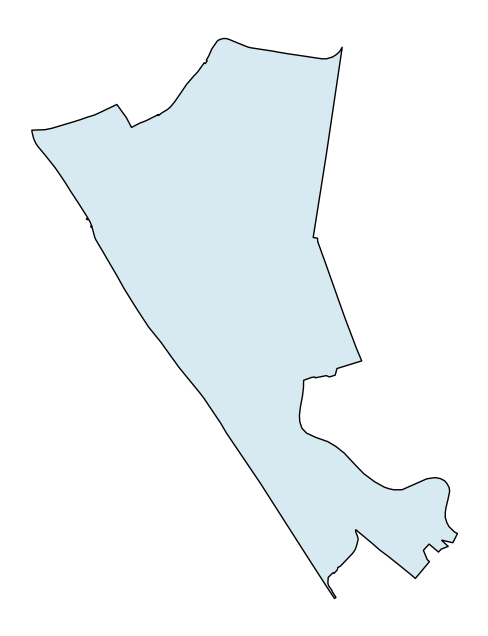

In [4]:
def download_boundary():
    out = ox.geocode_to_gdf(PLACE)
    assert len(out) == 1 and out.geom_type.isin(['Polygon', 'MultiPolygon']).all()
    label = str(out.iloc[0].get('display_name', ''))
    assert (('Невск' in label or 'Nevsk' in label) and
            ('Петербург' in label or 'Petersburg' in label)), f'Проверьте найденную территорию: {label}'
    return {'boundary': out.to_crs(LOCAL_EPSG)}

boundary_path = RAW / 'boundary.geojson'
boundary = stage('boundary', {'boundary': (boundary_path, 'geo')}, download_boundary,
                 params={'query': PLACE, 'source': 'OSM Nominatim'}, raw=True)['boundary']
display(boundary.drop(columns='geometry'))
print('Площадь границы, км²:', round(boundary.area.sum() / 1e6, 2))
boundary.plot(figsize=(10, 8), facecolor='#d8eaf1', edgecolor='black').set_axis_off()
plt.show()

## 3. Дороги, железные дороги и вода

Три запроса к OSM могут занять несколько минут. Эти объекты служат границами кварталов;
это **не построение транспортного графа**. Сохраняем исходные объекты до очистки.
При сетевой ошибке повторите ячейку позднее: не нужно удалять успешно полученные слои.

In [5]:
CUT_TAGS = {
    'roads': {'highway': ['construction', 'crossing', 'living_street', 'motorway',
        'motorway_link', 'motorway_junction', 'pedestrian', 'primary', 'primary_link',
        'raceway', 'residential', 'road', 'secondary', 'secondary_link', 'services',
        'tertiary', 'tertiary_link', 'track', 'trunk', 'trunk_link', 'turning_circle',
        'turning_loop', 'unclassified'], 'service': ['living_street', 'emergency_access']},
    'railways': {'railway': 'rail'},
    'water': {'riverbank': True, 'reservoir': True, 'basin': True, 'dock': True,
              'canal': True, 'pond': True, 'natural': ['water', 'bay'],
              'waterway': ['river', 'canal', 'ditch'], 'landuse': 'basin', 'water': 'lake'},
}
raw_cut = {}
for name, tags in CUT_TAGS.items():
    raw_cut[name] = stage(name, {name: (RAW / f'{name}.geojson', 'geo')},
                         lambda name=name, tags=tags: {name: features(tags)},
                         deps=[boundary_path], params={'tags': tags}, raw=True)[name]
    print(name, '— объектов:', len(raw_cut[name]))

roads: читаем готовые файлы
roads — объектов: 3354
railways: читаем готовые файлы
railways — объектов: 950
water: читаем готовые файлы
water — объектов: 155


## 4. Подготовить кварталы

BlocksNet уберёт водные территории и разделит район линиями дорог и железных дорог.
Полученные «кварталы» — аналитические участки, они не обязаны совпадать с кадастровыми.
Нарезка зависит от полноты OSM. Часть территории может не входить в кварталы из-за воды.

C:\games\urban\python-package-boilerplate\.venv\lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


blocks: читаем готовые файлы
Кварталов: 1461
Сумма площадей кварталов, км²: 56.8
Сохранено: C:\games\urban\python-package-boilerplate\examples\data\nevsky\prepared\blocks.geojson


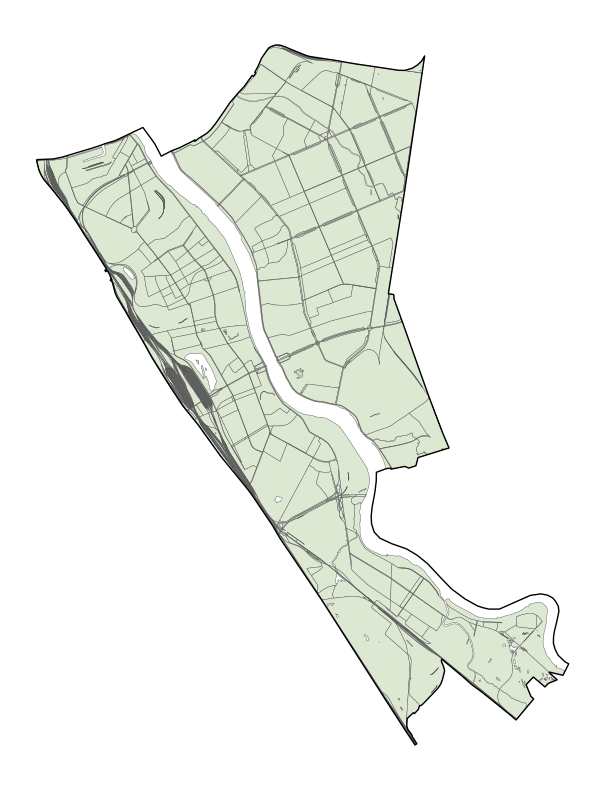

,geometry,block_id,area_m2
0,"POLYGON ((352578.955 6644730.362, 352576.757 6...",0,72.657202
1,"POLYGON ((352586.014 6644730.158, 352583.938 6...",1,78.164558
2,"POLYGON ((352589.212 6644730.269, 352587.26 66...",2,2070.246537
3,"POLYGON ((352737.548 6644737.725, 352737.561 6...",3,642.863532
4,"POLYGON ((352823.021 6644259.246, 352838.26 66...",4,6955.487188


In [6]:
from blocksnet.blocks.cutting import preprocess_urban_objects, cut_urban_blocks

blocks_path = READY / 'blocks.geojson'
def prepare_blocks():
    roads = clean_geometry(raw_cut['roads'], ['LineString', 'MultiLineString'], boundary)
    railways = clean_geometry(raw_cut['railways'], ['LineString', 'MultiLineString'], boundary)
    water = clean_geometry(raw_cut['water'], ['Polygon', 'MultiPolygon', 'LineString', 'MultiLineString'], boundary)
    assert not roads.empty, 'Нет дорог: проверьте исходную загрузку.'
    lines, polygons = preprocess_urban_objects(roads, railways, water)
    blocks = cut_urban_blocks(boundary[['geometry']].copy(), lines, polygons)
    blocks = clean_geometry(blocks, ['Polygon', 'MultiPolygon'], boundary)[['geometry']]
    blocks = blocks[blocks.area > 0].copy()
    assert not blocks.empty, 'Не получены кварталы. Покажите сообщение в чате.'
    blocks['_x'] = blocks.centroid.x
    blocks['_y'] = blocks.centroid.y
    blocks['_wkb'] = blocks.geometry.to_wkb(hex=True)
    blocks = blocks.sort_values(['_x', '_y', '_wkb']).drop(columns=['_x', '_y', '_wkb']).reset_index(drop=True)
    blocks.index = pd.Index(range(len(blocks)), name=None)
    blocks['block_id'] = blocks.index
    return {'blocks': blocks}

blocks = stage('blocks', {'blocks': (blocks_path, 'geo')}, prepare_blocks,
               deps=[boundary_path, *[RAW / f'{name}.geojson' for name in CUT_TAGS]],
               params={'epsg': LOCAL_EPSG, 'tags': CUT_TAGS})['blocks']
blocks.index = blocks.index.astype(int)
assert blocks.index.is_unique and blocks.geometry.is_valid.all()
print('Кварталов:', len(blocks))
print('Сумма площадей кварталов, км²:', round(blocks.area.sum() / 1e6, 2))
print('Сохранено:', blocks_path)
ax = blocks.plot(figsize=(12, 10), edgecolor='#555555', linewidth=0.3, color='#dce8d2')
boundary.boundary.plot(ax=ax, color='black', linewidth=1)
ax.set_axis_off()
plt.show()
display(blocks.assign(area_m2=blocks.area).head())

## ⛔ ОСТАНОВКА: сначала обсудить метрики

**На этом первый запуск заканчивается.** Проверьте границу и карту кварталов.
Напишите в чат: «Кварталы Невского района подготовлены. Какие метрики доступны и как их понимать?»
Пришлите число кварталов и замеченные проблемы. Не запускайте следующие расчёты до обсуждения.

Ниже уже подготовлен полный код. Он защищён проверкой, поэтому случайное «Запустить всё»
остановится здесь. После обсуждения замените **только** `CONTINUE_AFTER_BLOCKS = False` на `True`
в следующей ячейке и выполните её. При новом сеансе остановка снова действует по умолчанию,
если вы вернёте значение `False` перед сохранением.

In [7]:
CONTINUE_AFTER_BLOCKS = True

def require_analysis():
    if CONTINUE_AFTER_BLOCKS is not True:
        raise RuntimeError('Остановка после подготовки кварталов. Сначала обсудите метрики в чате. '
                           'Затем осознанно установите CONTINUE_AFTER_BLOCKS=True.')

require_analysis()
print('Следующие этапы разрешены вами. Запускайте по одной ячейке.')

Следующие этапы разрешены вами. Запускайте по одной ячейке.


## 5. Землепользование

Получаем OSM `landuse`, а не официальное функциональное зонирование генплана.
Назначение квартала выбирается по наибольшей площади пересечения. Непокрытые кварталы
сохраняются с отсутствующим назначением; неизвестные категории перечисляются отдельно.

functional_zones: читаем готовые файлы
land_use: читаем готовые файлы


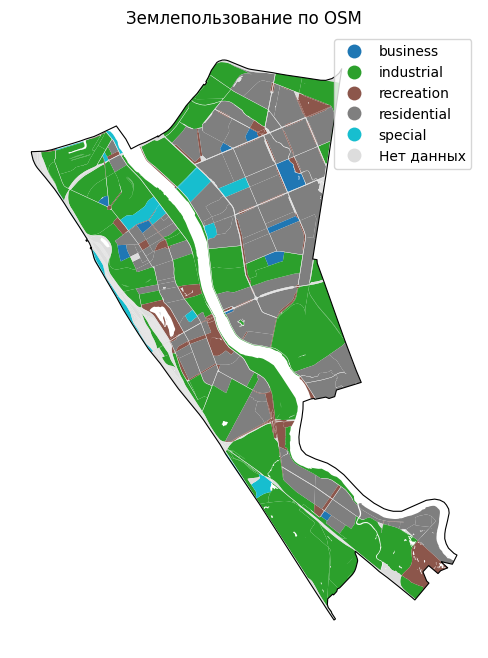

,Кварталов
land_use,
None,1076
recreation,156
residential,104
industrial,91
special,24
business,10


In [8]:
require_analysis()

from blocksnet.enums import LandUse
from blocksnet.blocks.assignment import assign_land_use

zones_path = RAW / 'functional_zones.geojson'
zones = stage('functional_zones', {'zones': (zones_path, 'geo')},
              lambda: {'zones': features({'landuse': True})}, deps=[boundary_path],
              params={'tags': {'landuse': True}}, raw=True)['zones']
RULES = {'commercial': LandUse.BUSINESS, 'industrial': LandUse.INDUSTRIAL,
         'cemetery': LandUse.SPECIAL, 'garages': LandUse.INDUSTRIAL,
         'residential': LandUse.RESIDENTIAL, 'retail': LandUse.BUSINESS,
         'grass': LandUse.RECREATION, 'farmland': LandUse.AGRICULTURE,
         'construction': LandUse.SPECIAL, 'brownfield': LandUse.INDUSTRIAL,
         'forest': LandUse.RECREATION, 'recreation_ground': LandUse.RECREATION,
         'religious': LandUse.SPECIAL, 'flowerbed': LandUse.RECREATION,
         'military': LandUse.SPECIAL, 'landfill': LandUse.TRANSPORT}

def prepare_land_use():
    if zones.empty:
        out = blocks.copy()
        out['land_use'] = None
        return {'land': out}
    functional = clean_geometry(zones, ['Polygon', 'MultiPolygon'], boundary)
    functional = functional[['geometry', 'landuse']].rename(columns={'landuse': 'functional_zone'})
    print('Категории без правила:', sorted(set(functional.functional_zone.dropna()) - set(RULES)))
    if functional.empty or not functional.functional_zone.isin(RULES).any():
        out = blocks.copy()
        out['land_use'] = None
        return {'land': out}
    # Передаём только геометрию: никакие числовые ID не суммируются/не перекрываются.
    out = assign_land_use(blocks[['geometry']].copy(), functional, RULES)
    out['land_use'] = out.land_use.map(serial_value)
    return {'land': out}

land_path = READY / 'blocks_land_use.geojson'
land = stage('land_use', {'land': (land_path, 'geo')}, prepare_land_use,
             deps=[blocks_path, zones_path], params={k: v.value for k, v in RULES.items()})['land']
map_column(land, 'land_use', 'Землепользование по OSM', categorical=True)
display(land.land_use.value_counts(dropna=False).rename('Кварталов').to_frame())

## 6. Здания: площади, этажность и оценка населения

Площадь пятна здания измеряется по его контуру. Общая площадь этажей оценивается как
пятно × этажность. Жилая площадь — доля от общей площади для жилых зданий.
Население оценивается по жилой площади и `LIVING_M2_PER_PERSON`.
Это **не перепись и не сведения о зарегистрированных жителях**.

При отсутствии этажности используется `DEFAULT_FLOORS=1`, как базовое допущение библиотеки.
Это может сильно занизить население высотных кварталов. Доля таких зданий будет показана.
Полигоны `building:part` отдельно не загружаются, чтобы не суммировать части вместе с целым зданием.

In [9]:
require_analysis()

from blocksnet.preprocessing.imputing import impute_buildings, impute_services
from blocksnet.blocks.aggregation import aggregate_objects

buildings_raw_path = RAW / 'buildings.geojson'
buildings_raw = stage('buildings_raw', {'buildings': (buildings_raw_path, 'geo')},
                      lambda: {'buildings': features({'building': True})},
                      deps=[boundary_path], params={'tags': {'building': True}}, raw=True)['buildings']
buildings_path = READY / 'buildings.geojson'
def prepare_buildings():
    out = clean_geometry(buildings_raw, ['Polygon', 'MultiPolygon'], explode=False)
    assert not out.empty, 'Не получены контуры зданий. Проверьте OSM и границу.'
    out = out[out['building'].notna() & ~out['building'].isin(['no', 'demolished', 'construction'])].copy()
    # Геометрию здания не обрезаем границей: иначе площадь краевых зданий будет занижена.
    out = out[['geometry', 'osm_key', 'building'] +
              [c for c in ['building:levels'] if c in out]].copy()
    out['is_living'] = out['building'].isin(['residential', 'house', 'apartments',
                                          'detached', 'terrace', 'dormitory'])
    levels = pd.to_numeric(out.get('building:levels', pd.Series(np.nan, index=out.index)), errors='coerce')
    out['floors_imputed'] = (levels.isna() | (levels <= 0)).astype(int)
    out['number_of_floors'] = levels.where(levels > 0).astype(float)
    for col in ['footprint_area', 'build_floor_area', 'living_area', 'non_living_area', 'population']:
        out[col] = np.nan
    out.loc[~out.is_living, 'population'] = 0.0
    out['population_estimated'] = out['is_living'].astype(int)
    imputed = impute_buildings(out, default_number_of_floors=DEFAULT_FLOORS,
                              living_area_coefficient=LIVING_AREA_COEFFICIENT,
                              default_living_demand=LIVING_M2_PER_PERSON)
    # Схемы BlocksNet отбрасывают дополнительные поля: сохраняем OSM-ключи и флаги отдельно.
    for col in imputed.columns:
        out[col] = imputed[col]
    return {'buildings': out}

buildings = stage('buildings_prepared', {'buildings': (buildings_path, 'geo')}, prepare_buildings,
                  deps=[buildings_raw_path], params={'floors': DEFAULT_FLOORS,
                  'living_coefficient': LIVING_AREA_COEFFICIENT, 'm2_per_person': LIVING_M2_PER_PERSON})['buildings']
print('Зданий:', len(buildings))
print('Без известной этажности:', f'{buildings.floors_imputed.mean():.1%}')
display(buildings.drop(columns='geometry').head())

buildings_raw: читаем готовые файлы
buildings_prepared: читаем готовые файлы
Зданий: 9386
Без известной этажности: 56.5%


,osm_key,building,building:levels,is_living,floors_imputed,number_of_floors,footprint_area,build_floor_area,living_area,non_living_area,population,population_estimated
0,relation/49586,college,4,False,0,4.0,4409.522447,17638.089789,0.0,17638.089789,0.0,0
1,relation/55902,yes,2,False,0,2.0,4169.892165,8339.784331,0.0,8339.784331,0.0,0
2,relation/227966,yes,None,False,1,1.0,4530.925349,4530.925349,0.0,4530.925349,0.0,0
3,relation/338785,school,3,False,0,3.0,2653.844801,7961.534402,0.0,7961.534402,0.0,0
4,relation/341710,school,3,False,0,3.0,2896.161052,8688.483156,0.0,8688.483156,0.0,0


In [10]:
ox.settings.overpass_url = "https://overpass.private.coffee/api"
ox.settings.overpass_rate_limit = False  # пропустить зависающую проверку /status
ox.settings.max_query_area_size = 2_500_000_000  # вернуть стандартный размер
ox.settings.requests_timeout = 180
ox.settings.log_console = True
ox.settings.use_cache = True

print("Настройки применены. Повтори шаг 7.")

Настройки применены. Повтори шаг 7.


## 7. Школы и вместимость

Используем объекты `amenity=school`. Числовое поле `capacity` берём из OSM, если оно есть.
Остальные значения заполняет BlocksNet минимальной вместимостью из своей конфигурации.
Число заполненных значений будет показано; это учебная оценка.

Точка школы внутри контура школы часто описывает один объект. Такие точки исключаем,
как и вложенные школьные контуры внутри большего школьного участка. Сохраняем список
исключений для ручной проверки: автоматическое правило может ошибиться при нескольких школах
в одном комплексе. Школы за границами района не учитываются.

In [11]:
require_analysis()

schools_raw_path = RAW / 'schools.geojson'
schools_raw = stage('schools_raw', {'schools': (schools_raw_path, 'geo')},
                    lambda: {'schools': features({'amenity': 'school'})},
                    deps=[boundary_path], params={'tags': {'amenity': 'school'}}, raw=True)['schools']
schools_path = READY / 'schools.geojson'
schools_removed_path = READY / 'schools_duplicates_review.geojson'
def prepare_schools():
    out = clean_geometry(schools_raw, ['Point', 'Polygon', 'MultiPolygon'], explode=False)
    if out.empty:
        raise RuntimeError('Не найдены школы. Не рассчитывайте обеспеченность без проверки источника.')
    out = out.drop_duplicates('osm_key').reset_index(drop=True)
    polys = out[out.geom_type.isin(['Polygon', 'MultiPolygon'])]
    remove = []
    for i, row in out.iterrows():
        if row.geometry.geom_type == 'Point':
            if any(polys.geometry.covers(row.geometry)):
                remove.append(i)
        elif row.geometry.geom_type in ['Polygon', 'MultiPolygon']:
            bigger = polys[polys.area > row.geometry.area]
            if any(bigger.geometry.covers(row.geometry)):
                remove.append(i)
    removed = out.loc[remove].copy()
    out = out.drop(index=remove).copy()
    capacities = pd.to_numeric(out.get('capacity', pd.Series(np.nan, index=out.index)), errors='coerce')
    out['capacity'] = capacities.where(capacities >= 0).astype(float)
    out['capacity_imputed'] = out.capacity.isna().astype(int)
    out['capacity'] = impute_services(out, 'school')['capacity']
    return {'schools': out, 'removed': removed}

school_bundle = stage('schools_prepared', {'schools': (schools_path, 'geo'),
                      'removed': (schools_removed_path, 'geo')}, prepare_schools, deps=[schools_raw_path])
schools = school_bundle['schools']
print('Школ после удаления возможных дублей:', len(schools))
print('Возможных дублей для проверки:', len(school_bundle['removed']))
print('Вместимость оценена для:', int(schools.capacity_imputed.sum()), 'школ')
display(schools[[c for c in ['osm_key', 'name', 'capacity', 'capacity_imputed'] if c in schools]])

schools_raw: читаем готовые файлы
schools_prepared: читаем готовые файлы
Школ после удаления возможных дублей: 89
Возможных дублей для проверки: 0
Вместимость оценена для: 87 школ


,osm_key,name,capacity,capacity_imputed
0,node/2325080237,Школа творческой фотографии «Аргентум»,250.0,1
1,node/3037052768,Школа индивидуального обучения «Шанс»,250.0,1
2,node/13252774272,Code Geass-R,10.0,0
3,relation/2731346,Школа № 570,250.0,1
4,relation/2758911,Школа № 327,250.0,1
...,...,...,...,...
84,way/1112322578,Школа № 691,250.0,1
85,way/1116140076,Школа № 557,250.0,1
86,way/1119967816,Школа № 717,250.0,1
87,way/1247482792,Школа № 566,250.0,1


## 8. Объединить здания и школы по кварталам

BlocksNet относит объект к кварталу по точке внутри его геометрии.
Школьные территории, а не отдельные здания школы, являются единицами подсчёта школ.
Непривязанные объекты сохраняются отдельно: их нельзя незаметно терять.
Числовые OSM-идентификаторы и этажности не суммируются как показатели.

aggregation: читаем готовые файлы
Непривязанные здания: 4 ; школы: 0
Расчётное население района: 717649


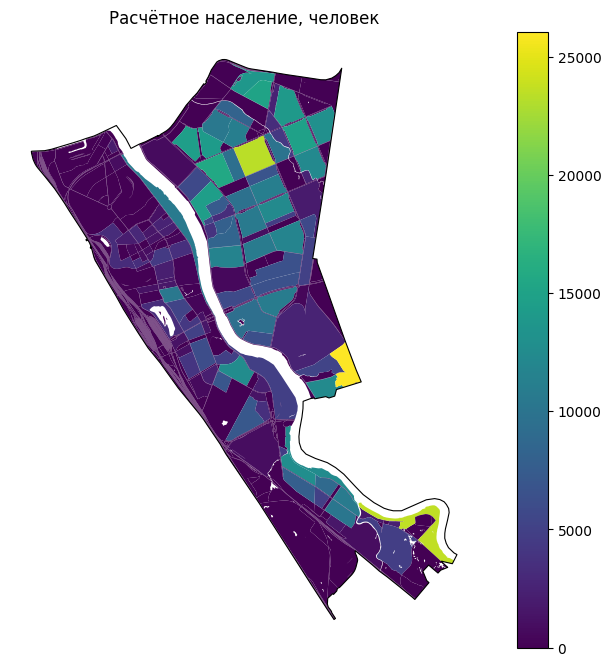

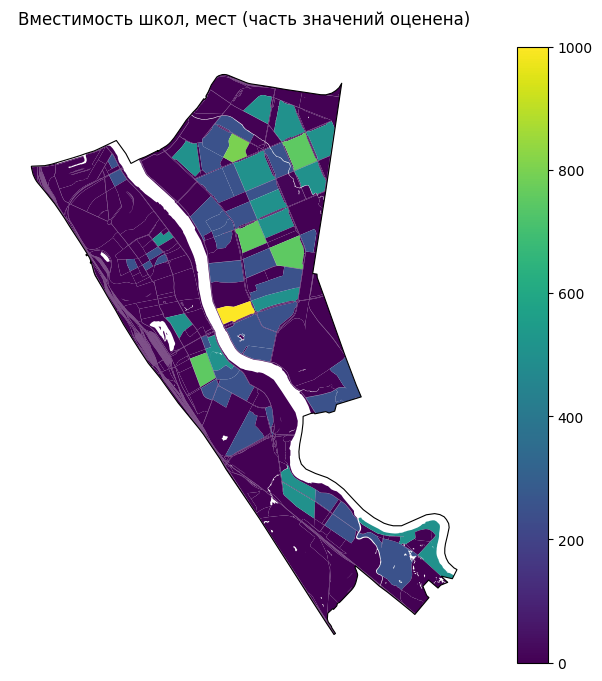

In [12]:
require_analysis()

building_blocks_path = READY / 'blocks_buildings.geojson'
school_blocks_path = READY / 'blocks_schools.geojson'
buildings_excess_path = READY / 'buildings_unassigned.geojson'
schools_excess_path = READY / 'schools_unassigned.geojson'
BUILDING_FIELDS = ['footprint_area', 'build_floor_area', 'living_area', 'non_living_area',
                   'population', 'floors_imputed', 'population_estimated']
def aggregate_inputs():
    # Проверяем неоднозначное попадание в несколько кварталов до суммирования.
    for title, objects in [('здания', buildings), ('школы', schools)]:
        points = objects[['geometry']].copy()
        points.geometry = points.representative_point()
        joined = points.sjoin(blocks[['geometry']], predicate='intersects')
        assert not joined.index.duplicated().any(), f'{title}: есть попадание в несколько кварталов.'
    bb, be = aggregate_objects(blocks[['geometry']].copy(), buildings[['geometry', *BUILDING_FIELDS]].copy())
    sb, se = aggregate_objects(blocks[['geometry']].copy(), schools[['geometry', 'capacity', 'capacity_imputed']].copy())
    bb = bb.rename(columns={'count': 'building_count'})
    sb = sb.rename(columns={'count': 'school_count'})
    # В отдельные файлы возвращаем исходные объекты с их OSM-ключами.
    return {'bb': bb, 'sb': sb, 'be': buildings.loc[be.index].copy(), 'se': schools.loc[se.index].copy()}

agg = stage('aggregation', {'bb': (building_blocks_path, 'geo'), 'sb': (school_blocks_path, 'geo'),
                           'be': (buildings_excess_path, 'geo'), 'se': (schools_excess_path, 'geo')},
            aggregate_inputs, deps=[blocks_path, buildings_path, schools_path])
building_blocks, school_blocks = agg['bb'], agg['sb']
print('Непривязанные здания:', len(agg['be']), '; школы:', len(agg['se']))
print('Расчётное население района:', round(building_blocks.population.sum()))
map_column(building_blocks, 'population', 'Расчётное население, человек')
map_column(school_blocks, 'capacity', 'Вместимость школ, мест (часть значений оценена)')

## 9. Скачать готовый автомобильный граф Санкт-Петербурга

Источник: [Mobility Sim Lab — Saint Petersburg](https://www.mobilitysimlab.com/saint-petersburg-maps/),
файл **11-saint petersburg.net.xml.gz**, готовая дорожная сеть SUMO.
Адрес файла проверен по странице источника при подготовке ноутбука; сам файл не загружался.
После вашего запуска он будет распакован как `saint_petersburg.net.xml`.
Скачивается только этот файл, не OSM-выгрузки и не интермодальная сеть.
Используется прямая ссылка со страницы источника; при изменении сайта остановитесь и сообщите в чат.
Можно самостоятельно скачать файл по ссылке на странице и указать путь в `MANUAL_GRAPH_PATH`.

Дата дорожных данных на странице не установлена; дата скачивания и SHA-256 будут записаны.
Условия повторного распространения файла сети отдельно не подтверждены:
для учебного использования сохраняем ссылку и не публикуем сам файл в репозитории.
Сеть целого города нужна, чтобы маршрут мог выходить за границу Невского района.

In [13]:
require_analysis()

import requests
import shutil
import gzip

GRAPH_PAGE = 'https://www.mobilitysimlab.com/saint-petersburg-maps/'
GRAPH_URL = 'https://mobilitysimlabcom.b-cdn.net/asia/11-saint%20petersburg/11-saint%20petersburg.net.xml.gz'
GRAPH_PATH = RAW / 'saint_petersburg.net.xml'
MANUAL_GRAPH_PATH = None  # путь к самостоятельно скачанному .net.xml или .net.xml.gz

def download_graph():
    partial = GRAPH_PATH.with_suffix('.download')
    unpacked = GRAPH_PATH.with_suffix('.unpacked')
    try:
        if MANUAL_GRAPH_PATH:
            source = Path(MANUAL_GRAPH_PATH).expanduser().resolve()
            assert source.is_file(), 'Не найден файл, указанный в MANUAL_GRAPH_PATH.'
            source_url = str(source)
        else:
            source_url = GRAPH_URL
            with requests.get(source_url, stream=True, timeout=(30, 300)) as response:
                response.raise_for_status()
                with partial.open('wb') as stream:
                    for chunk in response.iter_content(1024 * 1024):
                        if chunk:
                            stream.write(chunk)
            source = partial
        assert source.stat().st_size > 1000, 'Файл подозрительно мал.'
        with source.open('rb') as stream:
            compressed = stream.read(2) == b'\x1f\x8b'
        opener = gzip.open if compressed else open
        with opener(source, 'rb') as source_stream, unpacked.open('wb') as dest:
            shutil.copyfileobj(source_stream, dest)
        with unpacked.open('rb') as stream:
            start = stream.read(4096).lower()
        assert b'<net' in start and b'<html' not in start, 'Вместо сети получена HTML-страница.'
        unpacked.replace(GRAPH_PATH)
    finally:
        for temporary in [partial, unpacked]:
            if temporary.exists():
                temporary.unlink()
    source_info = {'page': GRAPH_PAGE, 'download': source_url, 'mode': 'passenger car',
                   'downloaded_utc': datetime.now(timezone.utc).isoformat(),
                   'sha256': file_hash(GRAPH_PATH), 'network_date': 'не указана на странице источника'}
    (RAW / 'graph_source.json').write_text(json.dumps(source_info, ensure_ascii=False, indent=2), encoding='utf-8')
    return {'graph_file': GRAPH_PATH, 'source_info': RAW / 'graph_source.json'}

stage('graph_download', {'graph_file': (GRAPH_PATH, 'file'),
                         'source_info': (RAW / 'graph_source.json', 'file')}, download_graph,
      params={'page': GRAPH_PAGE, 'url': GRAPH_URL, 'manual': MANUAL_GRAPH_PATH}, raw=True)
print('Готовая сеть:', GRAPH_PATH)
print('Размер, МБ:', round(GRAPH_PATH.stat().st_size / 1e6, 1))

graph_download: читаем готовые файлы
Готовая сеть: C:\games\urban\python-package-boilerplate\examples\data\nevsky\raw\saint_petersburg.net.xml
Размер, МБ: 1795.1


## 10А. Выделить сеть района с буфером 5 км

Исходный XML большого города слишком тяжёл для полной загрузки в Python. Сначала читаем
его **по одному XML-элементу**, два прохода по локальному файлу, без новых скачиваний.
Первый проход отбирает дороги, пересекающие район с буфером. Второй записывает только
отобранные дороги, их перекрёстки и внутренние соединения в меньший файл.
Память расходуется на текущий XML-элемент и номера отобранных дорог, а не на всю сеть.

Это выборка из готового графа, без построения интермодальной сети. Исходный файл не изменяется.
Дороги, пересекающие границу выборки, сохраняются целиком. Сеть не обрезается строго по району:
буфер нужен для маршрутов через мосты и соседние территории.

`GRAPH_BUFFER_M = 5000` — начальное учебное допущение. Оно не гарантирует сохранение всех
кратчайших маршрутов полной сети: часть дальних объездов может выйти за буфер.
После расчёта проверьте недостижимые пары и несколько маршрутов между берегами Невы.
Для проверки устойчивости можно повторить этап с 10000 м и сравнить результаты.
Изменение буфера автоматически обновляет производные файлы сети и последующие расчёты.

**Перед этим шагом:** остановите старое преобразование. Если оно долго не прерывается,
перезапустите ядро и выполните предыдущие разделы с `REFRESH_RAW=False` и
`REFRESH_DERIVED=False`. Сохранённые исходники и результаты будут прочитаны с диска.
Верните `CONTINUE_AFTER_BLOCKS=True` после предусмотренной остановки.

Потоковое выделение тоже требует прочитать большой файл с диска дважды. Точное время зависит
от компьютера. В журнале отображаются приблизительные проценты каждого прохода.

graph_region: выполняем этот этап; результат будет сохранён
Проход 1/2: отбор дорог вокруг района...
Проход 1/2: прочитано около 10%
Проход 1/2: прочитано около 20%
Проход 1/2: прочитано около 30%
Проход 1/2: прочитано около 40%
Проход 1/2: прочитано около 50%
Проход 1/2: прочитано около 60%
Проход 1/2: прочитано около 70%
Проход 1/2: прочитано около 80%
Проход 1/2: прочитано около 90%
Проход 1/2: прочитано около 100%
Отобрано внешних дорог: 43255 из 1157204
Проход 2/2: запись меньшего файла сети...
Проход 2/2: прочитано около 10%
Проход 2/2: прочитано около 20%
Проход 2/2: прочитано около 30%
Проход 2/2: прочитано около 40%
Проход 2/2: прочитано около 50%
Проход 2/2: прочитано около 60%
Проход 2/2: прочитано около 70%
Проход 2/2: прочитано около 80%
Проход 2/2: прочитано около 90%
Проход 2/2: прочитано около 100%
Файл для следующего шага: C:\games\urban\python-package-boilerplate\examples\data\nevsky\prepared\nevsky_buffer.net.xml
Размер выделенной сети, МБ: 103.3


,Выборка
external_edges,43255
source_external_edges,1157204
internal_edges,131358
connections,166462
junctions,30210
buffer_m,5000
source_bytes,1795139620
subset_bytes,103252620


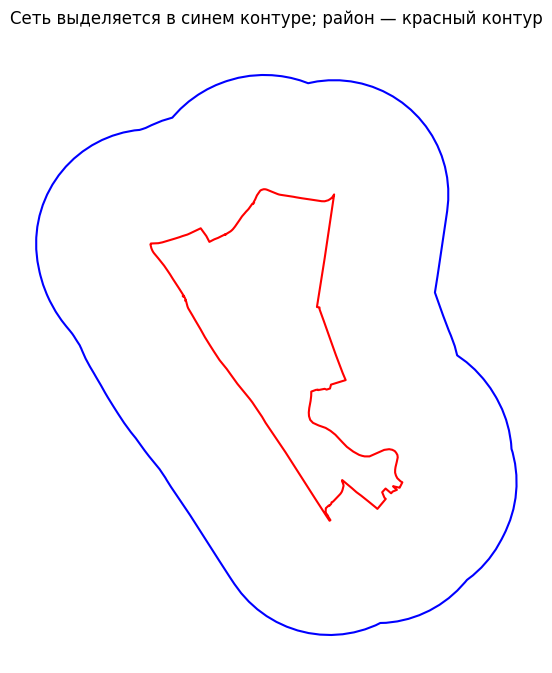

In [14]:
require_analysis()

import xml.etree.ElementTree as ET
from pyproj import CRS, Transformer
from shapely.geometry import LineString
from shapely.ops import transform as transform_geometry
from sumolib.net.lane import get_allowed

GRAPH_BUFFER_M = 5000
REGION_GRAPH_PATH = READY / 'nevsky_buffer.net.xml'
graph_context_path = READY / 'graph_context.geojson'
graph_selection_path = READY / 'graph_selection.json'

def top_level_elements(path, label):
    # Удаляем завершённые элементы из корня: iterparse иначе удерживает их в памяти.
    total = Path(path).stat().st_size
    with Path(path).open('rb') as stream:
        root, depth, next_percent = None, 0, 10
        for event, element in ET.iterparse(stream, events=('start', 'end')):
            if event == 'start':
                depth += 1
                if root is None:
                    root = element
            else:
                if depth == 2:
                    yield element
                    root.remove(element)
                    element.clear()
                    percent = int(100 * stream.tell() / total)
                    if percent >= next_percent:
                        print(f'{label}: прочитано около {percent}%', flush=True)
                        next_percent = (percent // 10 + 1) * 10
                depth -= 1

def xml_header(path):
    with Path(path).open('rb') as stream:
        root_attributes = None
        for event, element in ET.iterparse(stream, events=('start',)):
            if root_attributes is None:
                assert element.tag == 'net', 'В исходном файле нет корневого элемента SUMO net.'
                root_attributes = dict(element.attrib)
            elif element.tag == 'location':
                return root_attributes, dict(element.attrib)
    raise RuntimeError('В готовой сети отсутствует описание координат location.')

def shape_coordinates(text):
    # В SUMO возможна третья координата высоты; для отбора нужны только x и y.
    return [tuple(map(float, item.split(',')[:2])) for item in text.split()]

def internal_junction(edge_id):
    # То же правило, которое использует sumolib NetReader для внутренних рёбер.
    return edge_id[1:edge_id.rfind('_')] if edge_id.startswith(':') else None

def select_region_graph():
    assert GRAPH_BUFFER_M > 0
    root_attrs, location = xml_header(GRAPH_PATH)
    projection = location['projParameter']
    if projection in ['!', '-', '.']:
        raise RuntimeError('В сети нет стандартной географической проекции; нужен разбор её координат.')
    network_crs = CRS.from_user_input(projection)
    offset_x, offset_y = map(float, location['netOffset'].split(','))
    to_network = Transformer.from_crs(LOCAL_EPSG, network_crs, always_xy=True)
    context = gpd.GeoDataFrame({'buffer_m': [GRAPH_BUFFER_M]},
                               geometry=[boundary.geometry.union_all().buffer(GRAPH_BUFFER_M)], crs=LOCAL_EPSG)

    def network_coordinates(x, y, z=None):
        px, py = to_network.transform(x, y)
        return np.asarray(px) + offset_x, np.asarray(py) + offset_y

    area = transform_geometry(network_coordinates, context.geometry.iloc[0])
    xmin, ymin, xmax, ymax = area.bounds
    external_edges, junctions = set(), set()
    external_total = 0
    print('Проход 1/2: отбор дорог вокруг района...', flush=True)
    for element in top_level_elements(GRAPH_PATH, 'Проход 1/2'):
        if element.tag != 'edge' or element.get('function', '') != '':
            continue
        external_total += 1
        selected = False
        for lane in element.findall('lane'):
            if 'passenger' not in get_allowed(lane.get('allow'), lane.get('disallow')):
                continue
            coords = shape_coordinates(lane.get('shape', element.get('shape', '')))
            if len(coords) < 2:
                continue
            xs, ys = zip(*coords)
            if max(xs) < xmin or min(xs) > xmax or max(ys) < ymin or min(ys) > ymax:
                continue
            if LineString(coords).intersects(area):
                selected = True
                break
        if selected:
            external_edges.add(element.attrib['id'])
            junctions.update([element.attrib['from'], element.attrib['to']])
    assert external_edges, 'В буфере не найдены автомобильные дороги. Проверьте координаты готовой сети.'
    print(f'Отобрано внешних дорог: {len(external_edges)} из {external_total}', flush=True)

    written_edges, written_lanes, passenger_lanes = set(), set(), set()
    def keep_edge(edge_id):
        return edge_id in written_edges

    def keep_lane(lane_id):
        return bool(lane_id) and keep_edge(lane_id[:lane_id.rfind('_')])

    partial = REGION_GRAPH_PATH.with_suffix('.partial')
    counts = {'external_edges': len(external_edges), 'source_external_edges': external_total,
              'internal_edges': 0, 'connections': 0, 'junctions': 0, 'buffer_m': GRAPH_BUFFER_M}
    # Сохраняем исходные значения координат, скоростей, длин и разрешённых соединений.
    attrs = {k: v for k, v in root_attrs.items() if '}' not in k}
    header = ET.tostring(ET.Element('net', attrs), encoding='utf-8').rstrip()
    assert header.endswith(b'/>')
    header = header[:-2] + b'>'
    print('Проход 2/2: запись меньшего файла сети...', flush=True)
    try:
        with partial.open('wb') as dest:
            dest.write(b'<?xml version="1.0" encoding="UTF-8"?>\n' + header + b'\n')
            for element in top_level_elements(GRAPH_PATH, 'Проход 2/2'):
                tag = element.tag
                keep = False
                if tag in ['location', 'type']:
                    keep = True
                elif tag == 'edge':
                    edge_id = element.attrib['id']
                    function = element.get('function', '')
                    keep = ((function == '' and edge_id in external_edges) or
                            (function == 'internal' and internal_junction(edge_id) in junctions))
                    if keep:
                        written_edges.add(edge_id)
                        for lane in element.findall('lane'):
                            written_lanes.add(lane.attrib['id'])
                            if 'passenger' in get_allowed(lane.get('allow'), lane.get('disallow')):
                                passenger_lanes.add(lane.attrib['id'])
                        if function == 'internal':
                            counts['internal_edges'] += 1
                        # Удаляем необязательные ссылки на исключённые соседние полосы/рёбра.
                        if element.get('bidi') and not keep_edge(element.get('bidi')):
                            element.attrib.pop('bidi')
                        for lane in element.findall('lane'):
                            for neighbour in list(lane.findall('neigh')):
                                if not keep_lane(neighbour.get('lane', '')):
                                    lane.remove(neighbour)
                elif tag == 'junction':
                    keep = element.get('id') in junctions
                    if keep:
                        counts['junctions'] += 1
                        for attribute in ['incLanes', 'intLanes']:
                            element.set(attribute, ' '.join(lane for lane in element.get(attribute, '').split()
                                                           if keep_lane(lane)))
                        # Матрицы приоритетов нужны микросимуляции, но не нашему маршрутизатору.
                        for request in list(element.findall('request')):
                            element.remove(request)
                elif tag == 'connection':
                    keep = keep_edge(element.attrib['from']) and keep_edge(element.attrib['to'])
                    source_lane = element.attrib['from'] + '_' + element.attrib['fromLane']
                    target_lane = element.attrib['to'] + '_' + element.attrib['toLane']
                    keep = (keep and source_lane in passenger_lanes and target_lane in passenger_lanes
                            and 'passenger' in get_allowed(element.get('allow'), element.get('disallow')))
                    via = element.get('via', '')
                    if keep and via and via not in written_lanes:
                        raise RuntimeError('Соединение ссылается на внутреннюю полосу вне выборки: ' + via)
                    if keep and via and via not in passenger_lanes:
                        keep = False
                    if keep:
                        counts['connections'] += 1
                if keep:
                    dest.write(ET.tostring(element, encoding='utf-8') + b'\n')
            dest.write(b'</net>\n')
        assert counts['connections'] > 0 and counts['junctions'] > 0
        assert counts['junctions'] == len(junctions), 'В исходной сети не найдены все нужные перекрёстки.'
        partial.replace(REGION_GRAPH_PATH)
    finally:
        if partial.exists():
            partial.unlink()
    counts['source_bytes'] = GRAPH_PATH.stat().st_size
    counts['subset_bytes'] = REGION_GRAPH_PATH.stat().st_size
    graph_selection_path.write_text(json.dumps(counts, ensure_ascii=False, indent=2), encoding='utf-8')
    return {'network': REGION_GRAPH_PATH, 'context': context, 'selection': graph_selection_path}

region_bundle = stage('graph_region', {'network': (REGION_GRAPH_PATH, 'file'),
                      'context': (graph_context_path, 'geo'), 'selection': (graph_selection_path, 'file')},
                     select_region_graph, deps=[GRAPH_PATH, boundary_path],
                     params={'buffer_m': GRAPH_BUFFER_M, 'selector': 'stream-sumo-1'})
print('Файл для следующего шага:', REGION_GRAPH_PATH)
print('Размер выделенной сети, МБ:', round(REGION_GRAPH_PATH.stat().st_size / 1e6, 1))
display(pd.Series(json.loads(graph_selection_path.read_text(encoding='utf-8')), name='Выборка').to_frame())
ax = region_bundle['context'].boundary.plot(figsize=(10, 8), color='blue')
boundary.boundary.plot(ax=ax, color='red')
ax.set_title('Сеть выделяется в синем контуре; район — красный контур')
ax.set_axis_off()
plt.show()

## 10Б. Преобразовать выделенный граф

Теперь sumolib читает **только файл района с буфером**, а не исходную сеть целого города.
Сохраняются направления движения, разрешённые для автомобиля полосы и соединения.
Выбор полосы в начале дорожного участка свободный. Перестроения и ожидание светофора не моделируются.
Время участка = длина в метрах / скорость в м/с / 60, результат — **минуты**.
Для уменьшения накладных расходов координаты преобразуются сразу массивами точек одной полосы.
Журнал показывает стадии чтения, подготовки полос, соединений и сохранения GraphML.
Файл выборки предназначен для расчёта маршрутов; программы светофоров и матрицы приоритетов
микросимуляции в этой выборке не сохраняются.

graph_conversion: выполняем этот этап; результат будет сохранён
Читаем сеть района с буфером...
Подготавливаем автомобильные полосы...
Подготавливаем соединения полос...
Создаём слои узлов и связей...
Сохраняем GraphML...
Узлов: 352367 ; связей: 390234


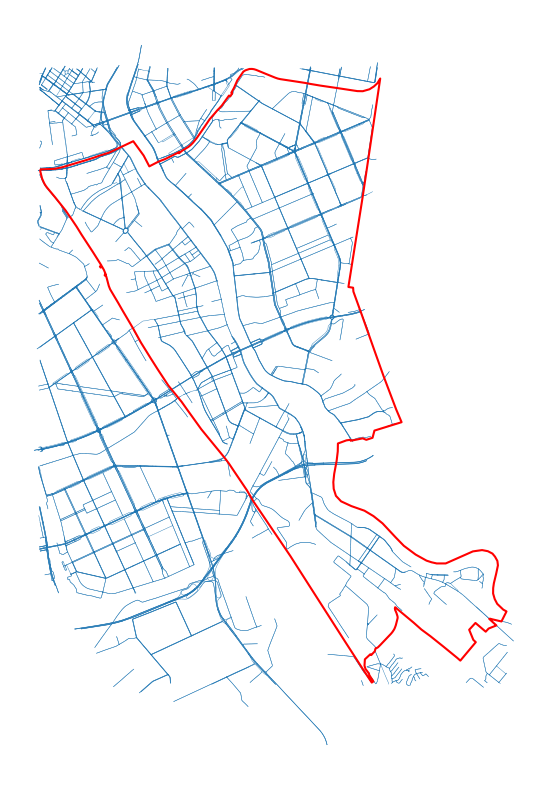

In [15]:
require_analysis()

import sumolib
import networkx as nx
from pyproj import Transformer
from shapely.geometry import Point, LineString

graph_nodes_path = READY / 'graph_nodes.geojson'
graph_edges_path = READY / 'graph_edges.geojson'
graphml_path = READY / 'drive.graphml'
def convert_ready_graph():
    print('Читаем сеть района с буфером...', flush=True)
    net = sumolib.net.readNet(str(REGION_GRAPH_PATH), withInternal=True,
                             withConnections=True, withFoes=False, maxcache=0)
    graph = nx.DiGraph(crs=LOCAL_EPSG, mode='passenger', weight='time_min')
    project = Transformer.from_crs(net.getGeoProj().crs, LOCAL_EPSG, always_xy=True)
    offset_x, offset_y = net.getLocationOffset()
    def project_shape(shape):
        xy = np.asarray(shape, dtype=float)
        xs, ys = project.transform(xy[:, 0] - offset_x, xy[:, 1] - offset_y)
        return list(zip(xs, ys))
    print('Подготавливаем автомобильные полосы...', flush=True)
    lanes = {lane.getID(): lane for edge in net.getEdges(withInternal=True)
             for lane in edge.getLanes() if lane.allows('passenger')}
    assert lanes, 'Нет полос для легкового автомобиля: проверьте файл сети.'
    shapes = {}
    for edge in net.getEdges(withInternal=False):
        allowed = [lane for lane in edge.getLanes() if lane.getID() in lanes]
        if allowed:
            px, py = project_shape(allowed[0].getShape()[:1])[0]
            graph.add_node(f'road:{edge.getID()}', x=float(px), y=float(py),
                           portal=True, lane_id='')
    for lane_id, lane in lanes.items():
        shape = lane.getShape()
        assert len(shape) >= 2 and lane.getSpeed() > 0 and lane.getLength() > 0
        coords = project_shape(shape)
        shapes[lane_id] = LineString(coords)
        external = not lane.getEdge().getID().startswith(':')
        for side, xy in [('in', coords[0]), ('out', coords[-1])]:
            graph.add_node(f'{lane_id}|{side}', x=float(xy[0]), y=float(xy[1]),
                           portal=False, lane_id=lane_id)
        if external:
            graph.add_edge(f'road:{lane.getEdge().getID()}', f'{lane_id}|in',
                           time_min=0.0, length_meter=0.0, kind='connection', lane_id='')
        graph.add_edge(f'{lane_id}|in', f'{lane_id}|out',
                       time_min=float(lane.getLength() / lane.getSpeed() / 60),
                       length_meter=float(lane.getLength()), kind='lane', lane_id=lane_id)
    print('Подготавливаем соединения полос...', flush=True)
    for lane_id, lane in lanes.items():
        for connection in lane.getOutgoing():
            if not connection.allows('passenger') or not connection.getToLane().allows('passenger'):
                continue
            via = connection.getViaLaneID()
            target = via if via else connection.getToLane().getID()
            if via and target not in lanes:
                raise RuntimeError(f'Не прочитана внутренняя полоса {via}; нельзя пропускать её молча.')
            if target in lanes:
                target_node = (f'{target}|in' if target.startswith(':')
                               else f'road:{lanes[target].getEdge().getID()}')
                graph.add_edge(f'{lane_id}|out', target_node, time_min=0.0,
                               length_meter=0.0, kind='connection', lane_id='')
    assert graph.number_of_edges() > len(lanes), 'Не найдены соединения полос.'
    from blocksnet.relations.accessibility.graph.schemas import validate_accessibility_graph
    validate_accessibility_graph(graph)
    lane = edge = allowed = connection = None
    del lanes, net
    print('Создаём слои узлов и связей...', flush=True)
    nodes = gpd.GeoDataFrame([
        {'node_id': node, **attrs, 'geometry': Point(attrs['x'], attrs['y'])}
        for node, attrs in graph.nodes(data=True)], crs=LOCAL_EPSG)
    edges = gpd.GeoDataFrame([
        {'source': u, 'target': v, **attrs, 'geometry': shapes[attrs['lane_id']]
         if attrs['kind'] == 'lane' else LineString([
             (graph.nodes[u]['x'], graph.nodes[u]['y']), (graph.nodes[v]['x'], graph.nodes[v]['y'])])}
        for u, v, attrs in graph.edges(data=True)], crs=LOCAL_EPSG)
    # В GraphML храним только простые атрибуты; геометрия — в GeoJSON.
    print('Сохраняем GraphML...', flush=True)
    nx.write_graphml(graph, graphml_path)
    return {'nodes': nodes, 'edges': edges, 'graphml': graphml_path}

graph_bundle = stage('graph_conversion', {'nodes': (graph_nodes_path, 'geo'),
                      'edges': (graph_edges_path, 'geo'), 'graphml': (graphml_path, 'file')},
                     convert_ready_graph, deps=[REGION_GRAPH_PATH],
                     params={'mode': 'passenger', 'epsg': LOCAL_EPSG,
                             'buffer_m': GRAPH_BUFFER_M, 'conversion': 'region-vectorized-1'})
graph_nodes, graph_edges = graph_bundle['nodes'], graph_bundle['edges']
print('Узлов:', len(graph_nodes), '; связей:', len(graph_edges))
ax = graph_edges.cx[boundary.total_bounds[0]:boundary.total_bounds[2],
                    boundary.total_bounds[1]:boundary.total_bounds[3]].plot(figsize=(12, 10), linewidth=0.3)
boundary.boundary.plot(ax=ax, color='red')
ax.set_axis_off()
plt.show()

## 11. Время между кварталами — в минутах

Квартал представлен точкой внутри его границы. Она привязывается к ближайшему входу
на внешнюю автомобильную полосу. Одинаково используем эту точку для отправления и прибытия.
Расстояние привязки сохраняется; если оно больше `MAX_SNAP_DISTANCE_M`, расчёт останавливается.
Не увеличивайте предел, пока не проверите карту: возможна неполнота сети или неверная территория.
Близость точки не гарантирует реальный подъезд через забор или другую преграду.

Матрица показывает **только движение по автомобильной сети**, без времени от точки квартала
до сети. Маршруты по разным направлениям могут различаться. Нет маршрута — `inf`, не ноль.
Диагональ равна нулю по определению модели. Несколько кварталов могут привязаться к одному входу;
тогда нулевое время между ними — ограничение пространственной детализации.

Для маршрутов используем алгоритм Дейкстры SciPy по подготовленному графу с весом `time_min`.
В отличие от обёртки IduEdu 0.4.1, он не удаляет компоненты сети перед привязкой и не добавляет
пешеходные подходы автоматически. Далее матрицу используют показатели BlocksNet.
Оценка растёт как квадрат числа кварталов; расчёт выполняется последовательно, без фоновых задач.

travel_time: выполняем этот этап; результат будет сохранён


,node_id,snap_distance_m
1199,road:-313776717#0,786.967111
1447,road:170531664#0,763.740505
1444,road:170531664#0,758.553072
1442,road:-338295508#7,757.805920
1446,road:170531664#0,752.386852
1449,road:170531664#0,740.714006
1452,road:-449108194,648.115337
1085,road:-416546607#2,415.900769
1392,road:-91664455#3,404.089465
1393,road:-91664455#3,402.897848


block_id,0,1,2,3,4
block_id,,,,,
0,0.000000,0.000000,0.151080,0.171476,2.231229
1,0.000000,0.000000,0.151080,0.171476,2.231229
2,1.739646,1.739646,0.000000,0.020396,2.080149
3,1.719250,1.719250,1.870329,0.000000,2.059754
4,3.484991,3.484991,3.636071,3.656466,0.000000


Недостижимых направленных пар: 44928
Разных входов сети: 852 для 1461 кварталов


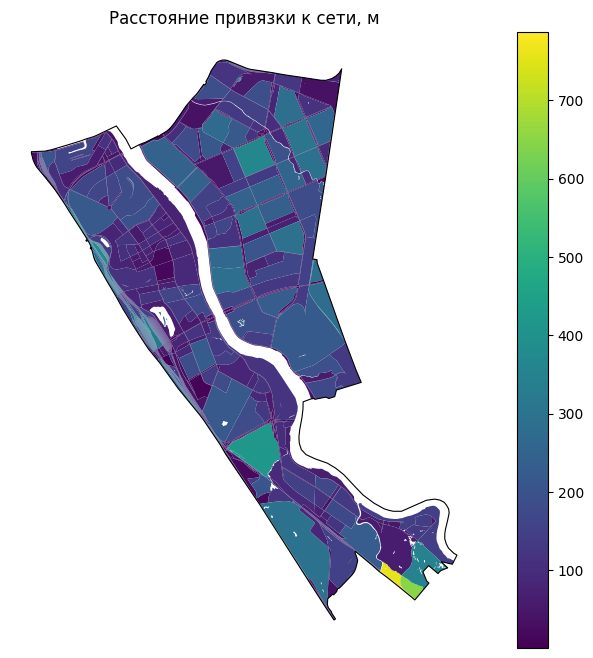

In [16]:
require_analysis()

from scipy.spatial import cKDTree
from scipy.sparse.csgraph import dijkstra

matrix_path = RESULTS / 'travel_time_minutes.parquet'
snap_path = READY / 'blocks_graph_snap.geojson'
def calculate_travel():
    graph = nx.read_graphml(graphml_path)
    graph.graph['crs'] = LOCAL_EPSG
    portals = graph_nodes[graph_nodes.portal.astype(bool)].copy()
    assert not portals.empty
    tree = cKDTree(np.column_stack([portals.geometry.x, portals.geometry.y]))
    points = blocks.representative_point()
    distances, positions = tree.query(np.column_stack([points.x, points.y]))
    snap = gpd.GeoDataFrame({'node_id': portals.iloc[positions].node_id.to_numpy(),
                            'snap_distance_m': distances}, geometry=points, crs=LOCAL_EPSG)
    snap.index = blocks.index
    display(snap.drop(columns='geometry').sort_values('snap_distance_m', ascending=False).head(10))
    assert np.max(distances) <= MAX_SNAP_DISTANCE_M, (
        'Слишком далёкая привязка: проверьте покрытие района готовой сетью. '
        'Матрица не рассчитана; не меняйте предел без проверки карты.'
    )
    names = list(graph.nodes)
    positions_by_id = {name: i for i, name in enumerate(names)}
    target_positions = np.array([positions_by_id[n] for n in snap.node_id], dtype=np.int32)
    weights = nx.to_scipy_sparse_array(graph, nodelist=names, weight='time_min', format='csr', dtype=float)
    # SciPy на Windows ожидает совместимый целочисленный тип индексов.
    weights.indices = weights.indices.astype(np.int32)
    weights.indptr = weights.indptr.astype(np.int32)
    values = np.full((len(blocks), len(blocks)), np.inf)
    for source in np.unique(target_positions):
        row = dijkstra(weights, directed=True, indices=int(source))
        values[target_positions == source] = row[target_positions]
    np.fill_diagonal(values, 0.0)
    matrix = pd.DataFrame(values, index=blocks.index, columns=blocks.index)
    matrix.index.name = 'block_id'
    matrix.columns = matrix.columns.astype(str)  # совместимость Parquet с pandas 2.x
    return {'matrix': matrix, 'snap': snap}

travel = stage('travel_time', {'matrix': (matrix_path, 'table'), 'snap': (snap_path, 'geo')},
               calculate_travel, deps=[blocks_path, graph_nodes_path, graphml_path],
               params={'max_snap_m': MAX_SNAP_DISTANCE_M, 'weight': 'time_min', 'approach_time': False})
acc_mx = travel['matrix'].copy()
acc_mx.index = acc_mx.index.astype(int)
acc_mx.columns = acc_mx.columns.astype(int)
acc_mx = acc_mx.loc[blocks.index, blocks.index]
snap = travel['snap']
acc_mx.to_csv(RESULTS / 'travel_time_minutes.csv', encoding='utf-8-sig', index_label='block_id')
assert not np.isnan(acc_mx.to_numpy()).any() and (acc_mx.to_numpy() >= 0).all()
assert np.allclose(np.diag(acc_mx), 0)
display(acc_mx.iloc[:5, :5])
offdiag = ~np.eye(len(blocks), dtype=bool)
print('Недостижимых направленных пар:', int((~np.isfinite(acc_mx.to_numpy()) & offdiag).sum()))
print('Разных входов сети:', snap.node_id.nunique(), 'для', len(blocks), 'кварталов')
map_column(blocks.join(snap[['snap_distance_m']]), 'snap_distance_m', 'Расстояние привязки к сети, м')

## 12. Конкурентная обеспеченность школами

Сохраняем все поля результата BlocksNet: спрос, нераспределённый спрос, остаток вместимости,
обслуживание внутри и вне порога, `provision_strong` и `provision_weak`, а также таблицу связей.
`max_depth=1` соответствует исходному pipeline: распределение только в пределах одного порога.
Поэтому сильная и слабая обеспеченность в этом сценарии могут совпадать.
Собственная вместимость квартала обслуживает его спрос без моделирования поездки внутри квартала.

Потребность на 1000 жителей и порог берутся из конфигурации установленной версии.
**Автомобильное время с этим порогом — учебный сценарий, не проверка нормативной пешей доступности.**
Можно задать свой `SCHOOL_CAR_THRESHOLD_MIN` в настройках после обсуждения.
Для кварталов без спроса доля обеспеченности не определена: оставляем пропуск, не заменяем нулём.

,Конфигурация BlocksNet для школы
name_ru,школа
demand,120
accessibility,15


school_provision: читаем готовые файлы


,demand,capacity,demand_left,demand_within,demand_without,capacity_left,capacity_within,capacity_without,provision_strong,provision_weak
0,0,0,0,0,0,0,0,0,NaN,NaN
1,0,0,0,0,0,0,0,0,NaN,NaN
2,0,0,0,0,0,0,0,0,NaN,NaN
3,0,0,0,0,0,0,0,0,NaN,NaN
4,0,0,0,0,0,0,0,0,NaN,NaN


,source,target,value
0,666,831,19.0
1,666,849,78.0
2,670,203,26.0
3,670,222,141.0
4,670,315,183.0


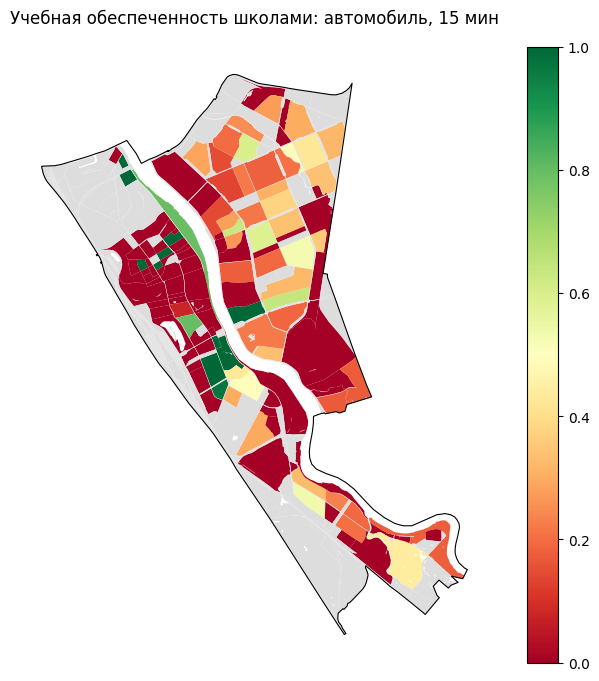

Линии связей — условные линии между кварталами, не геометрия маршрутов.


In [22]:
require_analysis()

from blocksnet.config import service_types_config
from blocksnet.analysis.provision import competitive_provision

school_config = service_types_config['school']
display(pd.Series(school_config, name='Конфигурация BlocksNet для школы').to_frame())
school_demand = int(school_config['demand'])
school_threshold = int(school_config['accessibility'] if SCHOOL_CAR_THRESHOLD_MIN is None
                       else SCHOOL_CAR_THRESHOLD_MIN)
assert school_demand > 0 and school_threshold > 0
provision_path = RESULTS / 'blocks_school_provision.geojson'
links_path = RESULTS / 'school_links.parquet'
def calculate_provision():
    inputs = building_blocks[['population']].join(school_blocks[['capacity']])
    assert inputs.notna().all().all()
    provision, links = competitive_provision(inputs, acc_mx, school_threshold, school_demand,
                                            self_supply=True, max_depth=1)
    links = links.reset_index()
    return {'provision': blocks[['geometry']].join(provision), 'links': links}

prov_bundle = stage('school_provision', {'provision': (provision_path, 'geo'), 'links': (links_path, 'table')},
                    calculate_provision, deps=[blocks_path, building_blocks_path, school_blocks_path, matrix_path],
                    params={'demand_per_1000': school_demand, 'car_threshold_min': school_threshold,
                            'self_supply': True, 'max_depth': 1})
provision, links = prov_bundle['provision'], prov_bundle['links']
display(provision.drop(columns='geometry').head())
display(links.head())
map_column(provision, 'provision_strong', f'Учебная обеспеченность школами: автомобиль, {school_threshold} мин',
           cmap='RdYlGn', vmin=0, vmax=1)
links.to_csv(RESULTS / 'school_links.csv', index=False, encoding='utf-8-sig')
if not links.empty:
    centers = blocks.representative_point()
    lines = [LineString([centers.loc[int(r.source)], centers.loc[int(r.target)]]) for r in links.itertuples()]
    links_geo = gpd.GeoDataFrame(links.copy(), geometry=lines, crs=LOCAL_EPSG)
else:
    links_geo = gpd.GeoDataFrame(links.copy(), geometry=[], crs=LOCAL_EPSG)
save_geo(links_geo, RESULTS / 'school_links.geojson')
print('Линии связей — условные линии между кварталами, не геометрия маршрутов.')

## 13. Плотность и характер застройки

Все показатели плотности исходного pipeline:

| Поле | Простой смысл |
|---|---|
| `fsi` | Площадь всех этажей / площадь квартала |
| `gsi` | Доля квартала под пятнами зданий (в BlocksNet ограничена сверху единицей) |
| `mxi` | Доля жилой площади в общей площади этажей |
| `l` | Средняя расчётная этажность: площадь этажей / пятна зданий |
| `osr` | Незастроенная площадь квартала / площадь этажей |
| `share_living` | Жилая площадь / пятна зданий; это отношение, может быть больше 1 |
| `share_non_living` | Нежилая площадь / пятна зданий; тоже может быть больше 1 |

Без зданий часть отношений не определена. Сохраняем пропуски, не изобретаем значения.
Spacematrix группирует застроенные кварталы по `fsi`, `l`, `mxi`; Strelka применяет фиксированные правила.
Названия типов — классификация модели, не официальная характеристика территории.
Spacematrix воспроизводится с `random_state=42`. Если уникальных сочетаний меньше 11,
число групп уменьшается с сообщением, а для совсем пустой застройки классификация пропускается.

density: читаем готовые файлы


,fsi,gsi,mxi,l,osr,share_living,share_non_living
count,1461.000000,1461.000000,287.000000,287.000000,287.000000,287.000000,287.000000
mean,0.113657,0.029394,0.300422,3.603229,65.479069,2.217337,1.385892
std,0.390555,0.085630,0.376181,4.015033,259.562657,3.789700,0.900100
min,0.000000,0.000000,0.000000,1.000000,-0.796831,0.000000,0.344432
25%,0.000000,0.000000,0.000000,1.000000,0.879865,0.000000,1.000000
50%,0.000000,0.000000,0.000000,1.609069,2.404031,0.000000,1.032243
75%,0.000000,0.000000,0.775406,4.741440,16.685359,3.577347,1.561028
max,5.408215,1.000000,0.900000,30.025178,2550.267031,26.869022,12.104065


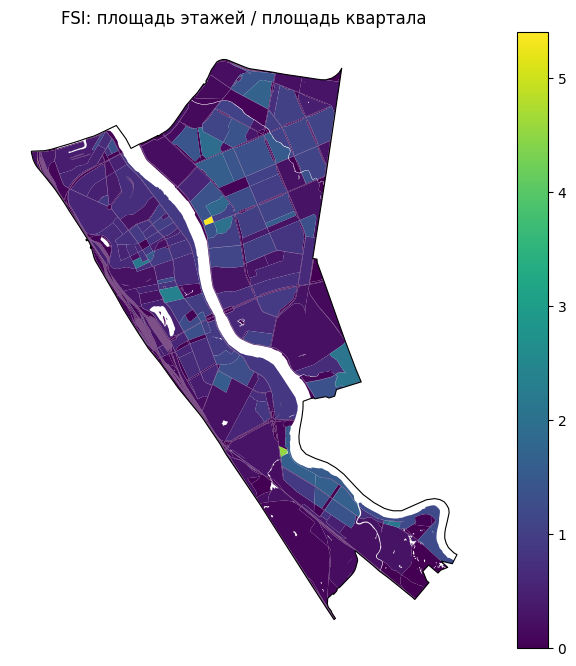

morphotypes: читаем готовые файлы


,l,fsi,mxi,l_interpretation,fsi_interpretation,mxi_interpretation,morphotype
cluster,,,,,,,
0,4.271431,0.733303,0.779841,mid-rise,low-density,residential,mid-rise low-density residential
1,1.000000,0.055622,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
2,13.080541,2.050744,0.822619,high-rise,high-density,residential,high-rise high-density residential
3,26.456929,4.971210,0.897342,tower,high-density,residential,tower high-density residential
4,1.000000,2.340462,0.000000,low-rise,high-density,non-residential,low-rise high-density non-residential
5,10.165196,1.392691,0.844437,high-rise,None,residential,high-rise residential
6,1.000000,4.922011,0.000000,low-rise,high-density,non-residential,low-rise high-density non-residential
7,1.995151,0.581124,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
8,7.205966,1.131312,0.813182,high-mid-rise,None,residential,high-mid-rise residential


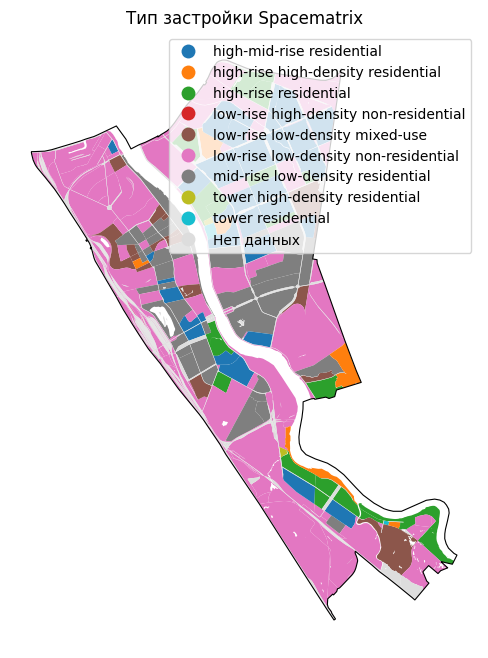

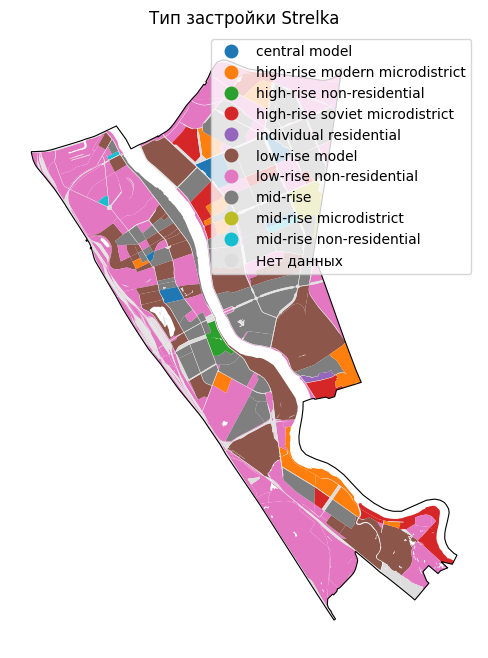

In [23]:
require_analysis()

from blocksnet.analysis.indicators import calculate_density_indicators
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes

density_path = RESULTS / 'blocks_density.geojson'
def calculate_density():
    inputs = building_blocks.copy()
    inputs['site_area'] = blocks.area
    values = calculate_density_indicators(inputs).replace([np.inf, -np.inf], np.nan)
    result = blocks[['geometry']].join(values)
    result['footprint_exceeds_site'] = result.footprint_area > result.site_area
    return {'density': result}

density = stage('density', {'density': (density_path, 'geo')}, calculate_density,
                deps=[blocks_path, building_blocks_path])['density']
density_cols = ['fsi', 'gsi', 'mxi', 'l', 'osr', 'share_living', 'share_non_living']
display(density[density_cols].describe())
map_column(density, 'fsi', 'FSI: площадь этажей / площадь квартала')

spacematrix_path = RESULTS / 'blocks_spacematrix.geojson'
strelka_path = RESULTS / 'blocks_strelka.geojson'
clusters_path = RESULTS / 'spacematrix_clusters.parquet'
def calculate_morphotypes():
    valid = density[['l', 'fsi', 'mxi']].replace([np.inf, -np.inf], np.nan).dropna()
    valid = valid[valid.fsi > 0]
    space = blocks[['geometry']].copy()
    space['cluster'] = np.nan
    space['morphotype'] = None
    strelka = blocks[['geometry']].copy()
    strelka['morphotype'] = None
    clusters = pd.DataFrame(columns=['l', 'fsi', 'mxi', 'morphotype'])
    if not valid.empty:
        k = min(SPACEMATRIX_CLUSTERS, len(valid), len(valid.drop_duplicates()))
        print('Число кластеров Spacematrix:', k)
        space_df, clusters = get_spacematrix_morphotypes(valid, n_clusters=k, random_state=RANDOM_STATE)
        strelka_df = get_strelka_morphotypes(valid)
        space.loc[space_df.index, 'cluster'] = space_df.cluster
        space.loc[space_df.index, 'morphotype'] = space_df.morphotype
        strelka.loc[strelka_df.index, 'morphotype'] = strelka_df.morphotype
    else:
        print('Нет подходящих застроенных кварталов для классификации.')
    return {'space': space, 'strelka': strelka, 'clusters': clusters}

morph = stage('morphotypes', {'space': (spacematrix_path, 'geo'), 'strelka': (strelka_path, 'geo'),
                              'clusters': (clusters_path, 'table')}, calculate_morphotypes,
              deps=[blocks_path, density_path], params={'k': SPACEMATRIX_CLUSTERS, 'seed': RANDOM_STATE})
spacematrix, strelka, clusters = morph['space'], morph['strelka'], morph['clusters']
display(clusters)
clusters.to_csv(RESULTS / 'spacematrix_clusters.csv', encoding='utf-8-sig', index_label='cluster')
map_column(spacematrix, 'morphotype', 'Тип застройки Spacematrix', categorical=True)
map_column(strelka, 'morphotype', 'Тип застройки Strelka', categorical=True)

## 14. Доступность территории с учётом площади кварталов

`area_accessibility` — среднее исходящее время до остальных кварталов, взвешенное по
их площади, включая собственный квартал с нулевым временем. Меньшее значение означает
более быстрое достижение территории **в пределах выбранного района**.
Если существует недостижимый квартал с ненулевой площадью, полное среднее время бесконечно.
В GeoJSON это будет пропуск с отдельной пометкой `area_accessibility_unreachable`.
Дополнительно показываем долю достижимых направлений; бесконечность не заменяем большим числом.

area_accessibility: читаем готовые файлы


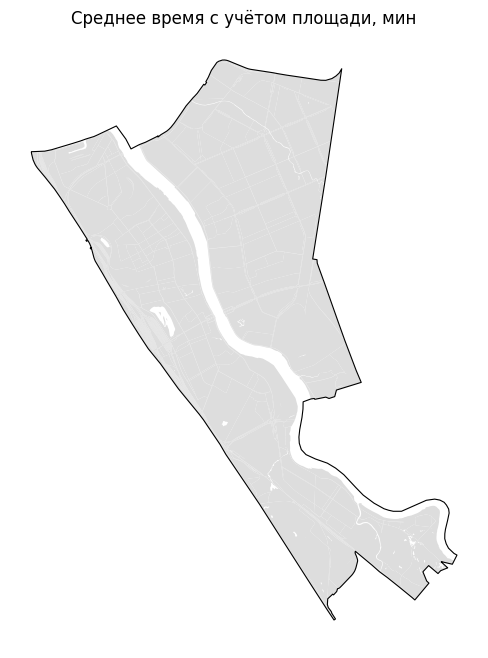

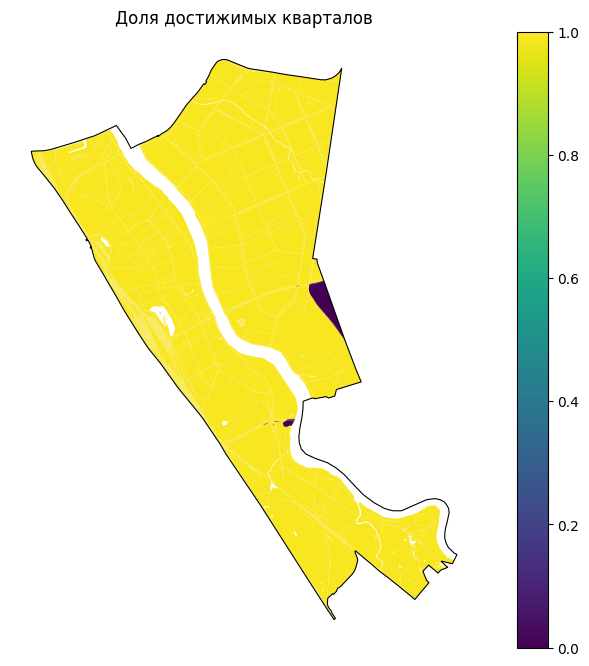

In [24]:
require_analysis()

from blocksnet.analysis.network import area_accessibility

area_acc_path = RESULTS / 'blocks_accessibility.geojson'
def calculate_area_access():
    inputs = pd.DataFrame({'site_area': blocks.area}, index=blocks.index)
    area = area_accessibility(acc_mx, inputs)
    unreachable = ~np.isfinite(area['area_accessibility'])
    area['area_accessibility_unreachable'] = unreachable.astype(int)
    area['area_accessibility'] = area['area_accessibility'].replace([np.inf, -np.inf], np.nan)
    finite = np.isfinite(acc_mx.to_numpy())
    np.fill_diagonal(finite, False)
    area['reachable_share'] = finite.sum(axis=1) / max(1, len(blocks) - 1)
    return {'area': blocks[['geometry']].join(area)}

area_acc = stage('area_accessibility', {'area': (area_acc_path, 'geo')}, calculate_area_access,
                 deps=[blocks_path, matrix_path])['area']
map_column(area_acc, 'area_accessibility', 'Среднее время с учётом площади, мин')
map_column(area_acc, 'reachable_share', 'Доля достижимых кварталов', vmin=0, vmax=1)

## 15. Итоговый набор для будущей HTML-страницы

Одна строка итогового GeoJSON — один квартал. Он содержит все показатели,
а таблицы связей, кластеров и времени сохраняются отдельно.
Графики сохраняются в PNG. Они не являются отдельной HTML-страницей: её создадим позже,
после проверки исследования. Все агрегаты и краткие выводы ниже основаны на тех же файлах.

,Значение
blocks,1461.000000
population_estimate,717649.000000
building_count,9382.000000
school_count,89.000000
school_capacity_estimate,22057.000000
school_threshold_car_minutes,15.000000
school_demand_per_1000,120.000000
provision_strong_total,0.253031
provision_weak_total,0.253031
unassigned_buildings,4.000000


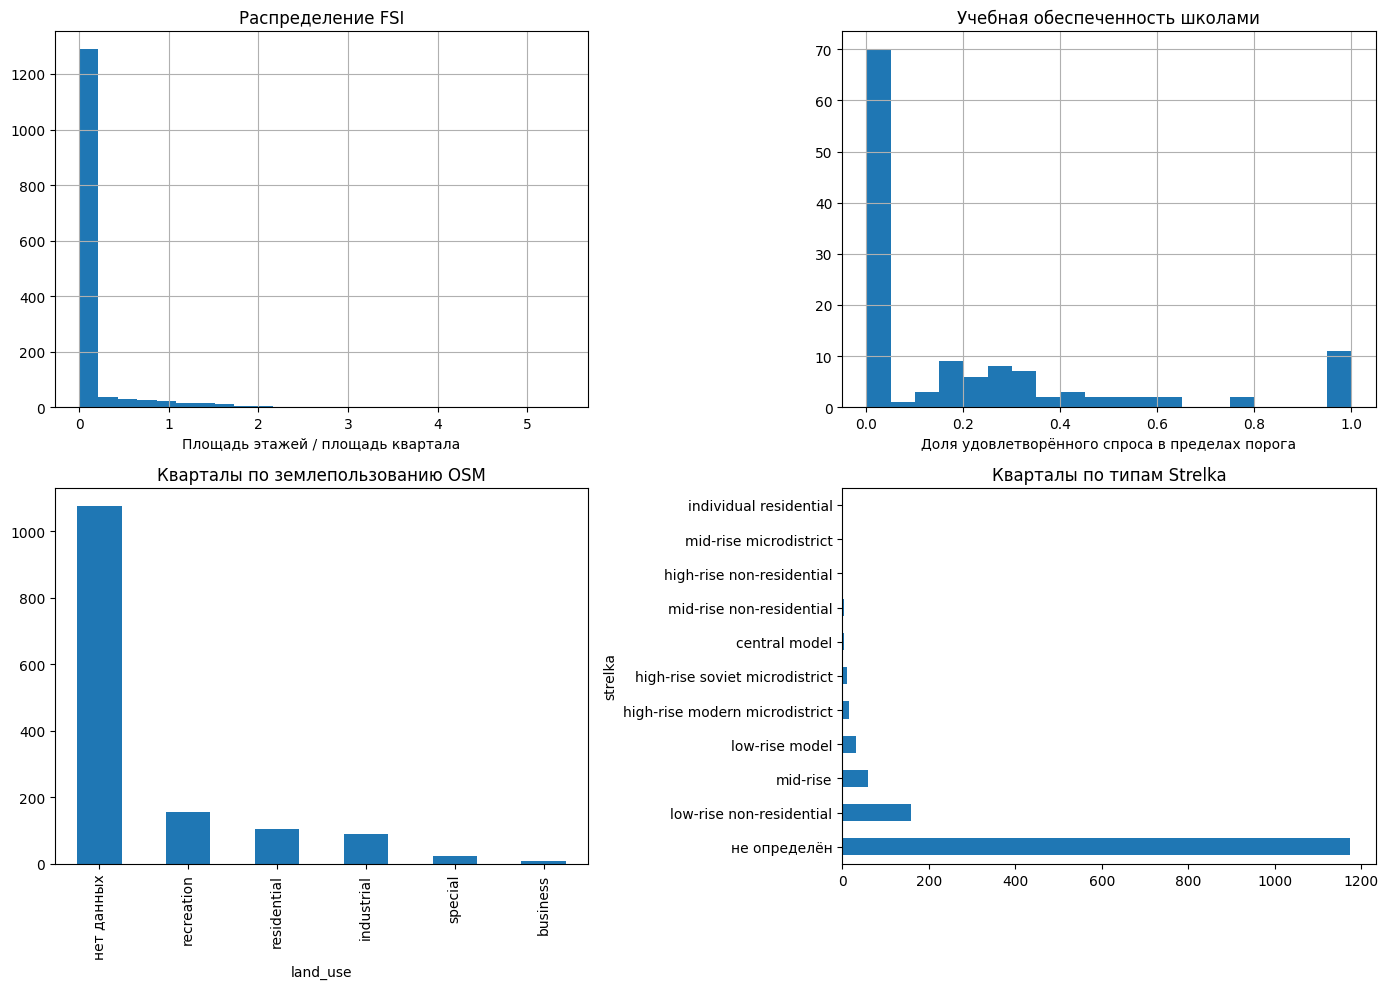

,block_id,land_use,footprint_area,build_floor_area,living_area,non_living_area,population,floors_imputed,population_estimated,building_count,...,provision_strong,provision_weak,cluster,spacematrix,strelka,area_accessibility,area_accessibility_unreachable,reachable_share,node_id,snap_distance_m
block_id,,,,,,,,,,,,,,,,,,,,,
1417,1417,residential,73697.355630,975462.220949,782086.804452,193375.416497,26061.0,28.0,18.0,71.0,...,0.174552,0.174552,2.0,high-rise high-density residential,high-rise modern microdistrict,None,1,0.990411,road:750218140#4,135.168518
1456,1456,residential,77653.989376,836076.811789,708284.792034,127792.019755,23601.0,114.0,16.0,137.0,...,0.176491,0.176491,5.0,high-rise residential,high-rise soviet microdistrict,None,1,0.990411,road:-1309570336#1,142.246751
1068,1068,residential,100960.119052,852788.196416,700996.909497,151791.286919,23349.0,5.0,40.0,100.0,...,0.182013,0.182013,8.0,high-mid-rise residential,mid-rise,None,1,0.990411,road:37406998#5,364.121558
1055,1055,residential,51392.248658,497813.779951,413601.945462,84211.834489,13779.0,28.0,15.0,61.0,...,0.000000,0.000000,5.0,high-rise residential,high-rise soviet microdistrict,None,1,0.990411,road:-370619185#11,57.757795
894,894,residential,100296.194796,740145.428871,467605.137508,272540.291363,15586.0,12.0,2.0,22.0,...,0.133618,0.133618,8.0,high-mid-rise residential,central model,None,1,0.990411,road:37629369#9,51.817015
848,848,residential,55629.655060,553218.045784,436721.549469,116496.496315,14553.0,16.0,10.0,48.0,...,0.143102,0.143102,5.0,high-rise residential,high-rise soviet microdistrict,None,1,0.990411,road:917882743#0,151.620369
1339,1339,industrial,26416.421821,427983.464099,373884.511461,54098.952638,12462.0,18.0,1.0,24.0,...,0.000000,0.000000,2.0,high-rise high-density residential,high-rise modern microdistrict,None,1,0.990411,road:339603103#3,67.922722
864,864,residential,49305.236348,554847.739373,426636.724658,128211.014715,14214.0,11.0,11.0,34.0,...,0.146542,0.146542,2.0,high-rise high-density residential,high-rise modern microdistrict,None,1,0.990411,road:-1226016684#2,213.690805
1092,1092,residential,53213.270963,540923.335494,454553.723487,86369.612007,15145.0,6.0,16.0,37.0,...,0.275028,0.275028,5.0,high-rise residential,high-rise modern microdistrict,None,1,0.990411,road:406326700#0,191.015224


In [25]:
require_analysis()

result = blocks[['geometry', 'block_id']].copy()
result = result.join(land[['land_use']])
result = result.join(building_blocks.drop(columns='geometry'))
result = result.join(school_blocks.drop(columns='geometry'))
result = result.join(density[['site_area', *density_cols, 'footprint_exceeds_site']])
prov_cols = [c for c in provision.columns if c not in ['geometry', 'population', 'capacity']]
result = result.join(provision[prov_cols])
result = result.join(spacematrix[['cluster', 'morphotype']].rename(columns={'morphotype': 'spacematrix'}))
result = result.join(strelka[['morphotype']].rename(columns={'morphotype': 'strelka'}))
result = result.join(area_acc.drop(columns='geometry'))
result = result.join(snap[['node_id', 'snap_distance_m']])
assert result.index.equals(blocks.index) and result.index.is_unique
save_geo(result, RESULTS / 'nevsky_blocks_results.geojson')
result.drop(columns='geometry').to_csv(RESULTS / 'nevsky_blocks_results.csv', encoding='utf-8-sig', index=False)

total_demand = provision.demand.sum()
summary = {
    'blocks': len(blocks), 'population_estimate': float(building_blocks.population.sum()),
    'building_count': int(building_blocks.building_count.sum()),
    'school_count': int(school_blocks.school_count.sum()),
    'school_capacity_estimate': float(school_blocks.capacity.sum()),
    'school_threshold_car_minutes': school_threshold,
    'school_demand_per_1000': school_demand,
    'provision_strong_total': float(provision.demand_within.sum() / total_demand) if total_demand else None,
    'provision_weak_total': float((provision.demand_within.sum() + provision.demand_without.sum()) / total_demand)
                            if total_demand else None,
    'unassigned_buildings': len(agg['be']), 'unassigned_schools': len(agg['se']),
}
(RESULTS / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.Series(summary, name='Значение').to_frame())
numeric_summary = result.select_dtypes(include='number').describe().T
numeric_summary.to_csv(RESULTS / 'indicators_summary.csv', encoding='utf-8-sig')

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
result.fsi.dropna().hist(ax=axes[0, 0], bins=25)
axes[0, 0].set_title('Распределение FSI')
axes[0, 0].set_xlabel('Площадь этажей / площадь квартала')
result.provision_strong.dropna().hist(ax=axes[0, 1], bins=20, range=(0, 1))
axes[0, 1].set_title('Учебная обеспеченность школами')
axes[0, 1].set_xlabel('Доля удовлетворённого спроса в пределах порога')
result.land_use.fillna('нет данных').value_counts().plot.bar(ax=axes[1, 0])
axes[1, 0].set_title('Кварталы по землепользованию OSM')
result.strelka.fillna('не определён').value_counts().plot.barh(ax=axes[1, 1])
axes[1, 1].set_title('Кварталы по типам Strelka')
fig.tight_layout()
fig.savefig(RESULTS / 'research_charts.png', dpi=150, bbox_inches='tight')
plt.show()
display(result.drop(columns='geometry').sort_values('demand_left', ascending=False).head(10))
result.drop(columns='geometry').sort_values('demand_left', ascending=False).head(10).to_csv(
    RESULTS / 'top_school_demand_left.csv', index=False, encoding='utf-8-sig')

In [26]:
# Берём исходный результат — повторный запуск не удвоит поправку.
fixed = prov_bundle["provision"].copy()

own = np.minimum(fixed["demand"], fixed["capacity"])
gap = fixed["capacity"] - (
    fixed["capacity_left"]
    + fixed["capacity_within"]
    + fixed["capacity_without"]
)

if np.allclose(gap, 0, rtol=0, atol=1e-6):
    print("Баланс уже корректен.")
else:
    assert np.allclose(gap, own, rtol=0, atol=1e-6), (
        "Расхождение отличается от известной ошибки. "
        "Остановитесь и пришлите это сообщение в чат."
    )
    fixed["capacity_within"] = fixed["capacity_within"] + own
    print("Учёт мест для жителей собственного квартала исправлен.")

assert np.allclose(
    fixed["capacity"],
    fixed["capacity_left"]
    + fixed["capacity_within"]
    + fixed["capacity_without"],
    rtol=0,
    atol=1e-6,
)

fixed["capacity_self_supply"] = own
fixed["capacity_accounting_adjustment"] = (
    fixed["capacity_within"] - prov_bundle["provision"]["capacity_within"]
)

provision = fixed
provision_checked_path = RESULTS / "blocks_school_provision_checked.geojson"
save_geo(provision, provision_checked_path)

print("Проверенный результат сохранён:", provision_checked_path)

Учёт мест для жителей собственного квартала исправлен.
Проверенный результат сохранён: C:\games\urban\python-package-boilerplate\examples\data\nevsky\results\blocks_school_provision_checked.geojson


## 16. Проверить результаты до выводов

Сначала изучите таблицу ниже и файлы непривязанных объектов/возможных дублей.
Сравните несколько знакомых кварталов с картой: школа действительно существует? Верна ли этажность?
Проверьте минимум три пары кварталов по обе стороны Невы и в разных частях района:
сетевое время должно выглядеть правдоподобно для автомобиля без пробок.
Не ожидайте совпадения с навигатором: модель не учитывает текущую дорожную ситуацию.

Пересечения пятен зданий, здания на границах, пропуски OSM и упрощённая этажность
могут искажать плотность и население. Обеспеченность школами у границы района зависит
от неучтённых школ и населения соседних районов. Эти ограничения входят в выводы.

In [27]:
require_analysis()

footprint_area_sum = blocks.area.sum()
overlap_area = max(0.0, footprint_area_sum - blocks.geometry.union_all().area)
offdiag = ~np.eye(len(blocks), dtype=bool)
checks = pd.DataFrame([
    ['Невалидные кварталы', int((~blocks.geometry.is_valid).sum()), 'ожидается 0'],
    ['Перекрытие кварталов, м²', overlap_area, 'около 0; иначе проверить геометрию'],
    ['Площадь вне границы, м²', float(blocks.geometry.difference(boundary.geometry.union_all()).area.sum()), 'около 0'],
    ['Непривязанные здания', len(agg['be']), 'проверить отдельный GeoJSON'],
    ['Непривязанные школы', len(agg['se']), 'проверить отдельный GeoJSON'],
    ['Исключённые школьные дубли', len(school_bundle['removed']), 'проверить вручную'],
    ['Здания без этажности, доля', float(buildings.floors_imputed.mean()), 'чем больше, тем слабее оценка населения'],
    ['Школы с оценённой вместимостью, доля', float(schools.capacity_imputed.mean()), 'сопоставить с известными данными'],
    ['Кварталы без землепользования', int(result.land_use.isna().sum()), 'не заменять произвольным назначением'],
    ['Пятна зданий больше квартала', int(density.footprint_exceeds_site.sum()), 'проверить пересечения и краевые здания'],
    ['Недостижимые пары', int((~np.isfinite(acc_mx.to_numpy()) & offdiag).sum()), 'проверить сеть и привязку'],
    ['Нулевые времена разных кварталов', int(((acc_mx.to_numpy() == 0) & offdiag).sum()), 'возможна общая привязка'],
    ['Максимальная привязка, м', float(snap.snap_distance_m.max()), 'проверить самые далёкие кварталы'],
], columns=['Проверка', 'Значение', 'Как читать'])
display(checks)
checks.to_csv(RESULTS / 'quality_checks.csv', index=False, encoding='utf-8-sig')
assert np.isclose(building_blocks.population.sum() + agg['be'].population.sum(), buildings.population.sum())
assert np.isclose(school_blocks.capacity.sum() + agg['se'].capacity.sum(), schools.capacity.sum())
assert (provision[['demand_left', 'capacity_left']] >= -1e-6).all().all()
assert np.allclose(provision.demand, provision.demand_left + provision.demand_within + provision.demand_without)
assert np.allclose(provision.capacity, provision.capacity_left + provision.capacity_within + provision.capacity_without)
assert provision.provision_strong.dropna().between(0, 1).all()
assert provision.provision_weak.dropna().between(0, 1).all()
if not links.empty:
    assert links.source.isin(blocks.index).all() and links.target.isin(blocks.index).all()
    assert all(acc_mx.loc[int(r.source), int(r.target)] <= school_threshold + 1e-6 for r in links.itertuples())
    assert links.value.sum() <= total_demand + 1e-6
assert len(load_geo(RESULTS / 'nevsky_blocks_results.geojson')) == len(blocks)
print('Проверки целостности пройдены. Содержательную проверку карты выполняете вы.')

,Проверка,Значение,Как читать
0,Невалидные кварталы,0.000000e+00,ожидается 0
1,"Перекрытие кварталов, м²",6.705523e-08,около 0; иначе проверить геометрию
2,"Площадь вне границы, м²",4.476931e-06,около 0
3,Непривязанные здания,4.000000e+00,проверить отдельный GeoJSON
4,Непривязанные школы,0.000000e+00,проверить отдельный GeoJSON
5,Исключённые школьные дубли,0.000000e+00,проверить вручную
6,"Здания без этажности, доля",5.649904e-01,"чем больше, тем слабее оценка населения"
7,"Школы с оценённой вместимостью, доля",9.775281e-01,сопоставить с известными данными
8,Кварталы без землепользования,1.076000e+03,не заменять произвольным назначением
9,Пятна зданий больше квартала,3.000000e+00,проверить пересечения и краевые здания


Проверки целостности пройдены. Содержательную проверку карты выполняете вы.


## 17. Сформулировать выводы и зафиксировать запуск

Автоматическая справка ниже описывает только полученные числа, без причинных объяснений.
Добавьте собственные наблюдения в следующую текстовую ячейку. Отрицательные результаты
и проблемы исходных данных — тоже результат учебного исследования.

In [28]:
require_analysis()

provision_total = summary['provision_strong_total']
provision_text = f'{provision_total:.1%}' if provision_total is not None else 'не определена (нет спроса)'
notes = (
    f'Исследовано кварталов: {len(blocks)}. Расчётное население: {summary["population_estimate"]:,.0f}.\n\n'
    f'Учтено школ: {summary["school_count"]}; вместимость: {summary["school_capacity_estimate"]:,.0f} мест. '
    f'Часть вместимостей оценена. Учебная обеспеченность при автомобильном пороге '
    f'{school_threshold} мин: {provision_text}.\n\n'
    'Это не официальная статистика населения и не оценка нормативной пешей доступности школ. '
    'Дорожная модель не учитывает пробки, светофорные задержки, парковку и подъезд внутри кварталов; '
    'не учитываются школы и спрос соседних районов. Проверьте quality_checks.csv перед интерпретацией.\n'
)
(RESULTS / 'findings_draft.txt').write_text(notes, encoding='utf-8')
display(Markdown(notes))
run_info = {'utc': datetime.now(timezone.utc).isoformat(), 'place': PLACE, 'versions': VERSIONS,
            'local_epsg': LOCAL_EPSG, 'cache_schema': CACHE_SCHEMA,
            'parameters': {'floors': DEFAULT_FLOORS, 'living_coefficient': LIVING_AREA_COEFFICIENT,
                           'm2_per_person': LIVING_M2_PER_PERSON, 'spacematrix_k': SPACEMATRIX_CLUSTERS,
                           'seed': RANDOM_STATE, 'max_snap_m': MAX_SNAP_DISTANCE_M,
                           'school_demand': school_demand, 'car_threshold_min': school_threshold},
            'graph': json.loads((RAW / 'graph_source.json').read_text(encoding='utf-8')),
            'graph_selection': json.loads(graph_selection_path.read_text(encoding='utf-8')),
            'sources': {'osm': 'https://www.openstreetmap.org/copyright',
                        'pipeline': 'https://github.com/aimclub/blocksnet/blob/main/examples/pipeline.ipynb'},
            'result_hashes': {p.name: file_hash(p) for p in RESULTS.iterdir() if p.is_file() and p.name != 'run_info.json'}}
(RESULTS / 'run_info.json').write_text(json.dumps(run_info, ensure_ascii=False, indent=2), encoding='utf-8')
print('Результаты сохранены:', RESULTS)

Исследовано кварталов: 1461. Расчётное население: 717,649.

Учтено школ: 89; вместимость: 22,057 мест. Часть вместимостей оценена. Учебная обеспеченность при автомобильном пороге 15 мин: 25.3%.

Это не официальная статистика населения и не оценка нормативной пешей доступности школ. Дорожная модель не учитывает пробки, светофорные задержки, парковку и подъезд внутри кварталов; не учитываются школы и спрос соседних районов. Проверьте quality_checks.csv перед интерпретацией.


Результаты сохранены: C:\games\urban\python-package-boilerplate\examples\data\nevsky\results


### Мои наблюдения — заполнить после проверки

1. Какие кварталы имеют наиболее интенсивную застройку? Совпадает ли это с известной картиной района?
2. Где остался наибольший спрос на школы? Насколько надёжны там население и вместимость?
3. Как различается автомобильная доступность на разных берегах Невы?
4. Где модель дала странный результат и какие исходные данные нужно уточнить?
5. Как изменились бы выводы при другой этажности по умолчанию и другом пороге поездки?

Для будущей HTML-страницы сохраните отредактированные выводы отдельно в
`examples/data/nevsky/results/findings_reviewed.txt`. Черновик формируется автоматически
и при повторном запуске заменяется; файл `findings_reviewed.txt` ноутбук не перезаписывает.

## 18. Повторный запуск и следующий этап

1. Откройте PowerShell в папке проекта и выполните:

   ```powershell
   .\.venv\Scripts\python.exe -m jupyter notebook .\examples\nevsky_research.ipynb
   ```

2. Выберите Python проекта. Выполните ячейки сверху вниз. Оставьте `REFRESH_RAW=False`
   и `REFRESH_DERIVED=False`: будут прочитаны сохранённые файлы.
3. На остановке после кварталов продолжайте только после обсуждения метрик.
   Установите `CONTINUE_AFTER_BLOCKS=True` и выполните ячейку остановки.
4. Если поменяли только оценочные параметры, повторите настройки и соответствующие этапы
   с последующими ячейками по порядку. Надёжнее перезапустить ядро и пройти сверху:
   зависимости файлов обновят производные результаты. Одна загрузка исходников не обновляет
   уже находящиеся в памяти таблицы; не перескакивайте ячейки.
5. Для полного пересчёта из сохранённых данных поставьте `REFRESH_DERIVED=True`.
   Для обновления OSM и готовой сети — `REFRESH_RAW=True`. Это отдельное осознанное действие;
   старые исходники заменятся. Для сохранения старого исследования сначала скопируйте всю папку
   `examples/data/nevsky` через Проводник. После обновления верните оба переключателя в `False`.
6. При ручном редактировании алгоритмов увеличьте `CACHE_SCHEMA`, чтобы не прочитать старые результаты.
   При ошибке связи повторите загрузку позднее. При ошибке структуры сети или странной геометрии
   остановитесь и пришлите текст ошибки в чат; не заменяйте отсутствующие данные нулями.

**Что сохраняется:**

| Папка | Содержание |
|---|---|
| `raw` | Исходные GeoJSON, готовый `.net.xml`, источники и дата загрузки |
| `prepared` | Кварталы, здания, школы, привязка и сеть GraphML + GeoJSON, журналы этапов |
| `results` | Итоговый GeoJSON кварталов, все расчётные слои, CSV/Parquet времени и связей, кластеры, графики, проверки и выводы |

GeoJSON предназначен для карт; матрица без геометрии дополнительно хранится в CSV и Parquet.
`inf` в матрице означает отсутствие маршрута. В итоговом GeoJSON бесконечные значения заменены
на `null` с отдельным признаком недостижимости. Не считайте такие кварталы доступными за ноль минут.

После самостоятельного выполнения сообщите в чат о результатах проверок. Затем отдельным этапом
создадим Python-файл для **одной HTML-страницы** с интерактивной картой, всеми показателями,
таблицами, графиками и проверенными выводами из этих файлов. Ноутбук сейчас HTML не создаёт.